![Banner](../images/09_capstones.png)

# Diabetes and Obesity in US Counties: Multivariate Poisson Cokriging

**A geostatistical capstone on county health counts, 2020 to 2024**

This is Capstone 5 of the geostatistics module (Part 9). It applies multivariate Poisson cokriging (Payares-Garcia et al., 2024) to diagnosed diabetes in the 3,108 counties of the conterminous United States, with obesity and physical inactivity as auxiliary variables. The questions are practical ones for a health department: how much do obesity and inactivity sharpen the estimate of diabetes risk in a county, how well can diabetes be predicted in counties or whole states where it was not measured, and where is the estimate least reliable?

**Data:** five-year (2020 to 2024) county means from the CDC U.S. Diabetes Surveillance System (USDSS), with population and social covariates, built by `build_diabetes_obesity_data.py` (`Data/00_shared/data_geostatistics/USA_Data/diabetes_obesity_county_2020_2024.csv`). County polygons: `Data/00_shared/data_geostatistics/US_COUNTY.shp`; state outlines: `Data/00_shared/data_geostatistics/US_STATE.shp`.

**Target:** adults with diagnosed diabetes (count) over adults (population at risk).
**Auxiliaries:** adults with obesity and physically inactive adults.

**Library:** `geolattice.geostatistics.kriging.multi_poisson_kriging`

## Overview

A county rate is a count divided by a population. Its reliability depends on that population: a rate from 2,000 adults scatters far more around the true risk than a rate from 2 million. Poisson kriging (Monestiez et al., 2006; Goovaerts, 2005) builds this into kriging. It treats each count as Poisson given the underlying risk, removes the population-dependent noise from the semivariogram, and adds an error term of size m*/n to the diagonal of the kriging matrix, so small counties get less weight and are smoothed more.

Payares-Garcia et al. (2024) extended this to several diseases at once. Each count is modelled as multivariate Poisson, so two diseases share a joint risk at the same location. The risks are linked by a linear model of coregionalization (LMC), and the cokriging system carries Poisson terms for the variances and for the covariances between diseases measured in the same area. Their application predicted HIV incidence in 66 Pennsylvania counties, where 30% of the counts were suppressed, from HIV prevalence, chlamydia and gonorrhea.

Diabetes and obesity are a natural pair for this method. Obesity is the strongest modifiable risk factor for type 2 diabetes, and physical inactivity adds to both. If the three risks share spatial structure, counties with obesity and inactivity data carry information about diabetes, even where diabetes itself is missing.

### Objectives

| Objective | Question | Sections |
|---|---|---|
| 1. Prepare the data | What do the counts and populations look like, and which counties have gaps? | 1 |
| 2. Describe the data | How noisy are the rates, and how strongly are the three risks related? | 2 |
| 3. Model the spatial structure | What are the Poisson semivariograms and cross-semivariograms, and what LMC fits them? | 3 and 4 |
| 4. Smooth | How much does cokriging improve the leave-one-out estimate of diabetes risk in every county? | 5 |
| 5. Predict | How well is diabetes predicted where it is hidden, at random or for whole states? | 6 |
| 6. Test the choices | How sensitive are the results to the neighbourhood, model and error term? | 7 |
| 7. Report | Where is risk high, how does it relate to social conditions, and where is the estimate least reliable? | 8 and 9 |

### Design notes

- **Crude risk.** Poisson cokriging models crude risk, cases over adults. USDSS age-adjusted percentages are kept only for comparison.
- **The counts are model-based estimates.** USDSS county numbers come from small-area models of survey data (BRFSS), not from registers. Section 2 compares their reported standard errors with Poisson noise, and Section 7 repeats the analysis with those standard errors as the error term.
- **Inactivity counts are approximate.** USDSS gives inactivity only as an age-adjusted percentage, so the count is that percentage times the adult population.
- **Local neighbourhoods.** With 3,108 counties and three variables, every prediction uses the k nearest counties of each variable (`number_of_neighbors`). Leave-one-out smoothing drops the county's own diabetes count and keeps its own obesity and inactivity counts.
- **Rates in percent.** All rates are in percent (`pop_rate = 100`), so semivariances are in squared percentage points.

## Setup

**Installation.** This notebook needs installation option 4 (core, spatial analysis, spatial statistics and geostatistics): `pip install "geolattice[geostats]"`. See "Installation options" in the GeoLattice README.

In [1]:
# Inline figures, table and map libraries, and the Poisson cokriging routines
%matplotlib inline
import sys, time, warnings
warnings.filterwarnings("ignore")
sys.modules.setdefault("tensorflow", None)   # keep optional TensorFlow backends out of this process

from pathlib import Path

import numpy as np
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
from matplotlib.colors import TwoSlopeNorm
from scipy import stats
from scipy.spatial import cKDTree
from scipy.stats import norm

# Multivariate Poisson cokriging, plus a check for a usable GPU
import geolattice.geostatistics as gstat
from geolattice.geostatistics.kriging import multi_poisson_kriging as mpk
from geolattice.geostatistics.utils.backend import cupy_gpu_usable

# Figure style, wide table display, and the seed for the masking experiments
plt.rcParams["figure.dpi"] = 100
plt.rcParams["axes.grid"] = True
plt.rcParams["grid.alpha"] = 0.3
pd.set_option("display.max_colwidth", None)
pd.set_option("display.width", 160)
SEED = 42

USE_GPU = cupy_gpu_usable()
print("geolattice.geostatistics :", gstat.__version__)
print("Backend             :", "GPU (CuPy)" if USE_GPU else "CPU (NumPy)")

# Percent scale, the three outcomes, and the lag and neighbourhood choices used later
PR = 100.0                 # rates in percent
VARS = ["diab", "obes", "inact"]
LABEL = {"diab": "Diagnosed diabetes", "obes": "Obesity", "inact": "Physical inactivity"}
MAXD = 800                 # km, maximum lag used to fit the LMC
NBINS = 16                 # lag classes (50 km wide)
K = 32                     # neighbours per variable
N_REPS = 10        # replicates of each random masking design
HOLDOUT_STATES = ["Kentucky", "Tennessee", "Florida", "Pennsylvania"]

geolattice.geostatistics : 0.3.49
Backend             : GPU (CuPy)


## Data

The data set holds five-year means of the USDSS county estimates (2020 to 2024), the mean adult population (2020 to 2023 population estimates times the adult share), and social and economic covariates. The county polygons come from `US_COUNTY.shp` (NAD 1983 Albers). The coordinates used for kriging are the polygon centroids in kilometres.

In [2]:
# Walk up from the working directory until the county shapefile is found
ROOT = Path.cwd().resolve()
while not (ROOT / "Data" / "00_shared" / "data_geostatistics" / "US_COUNTY.shp").is_file():
    if ROOT.parent == ROOT:
        raise FileNotFoundError("Could not find Data/00_shared/data_geostatistics/US_COUNTY.shp. "
                                "Run this notebook from the GeoLattice repository.")
    ROOT = ROOT.parent
DATA = ROOT / "Data" / "00_shared" / "data_geostatistics"

# County table and polygons. FIPS is zero-padded, and shapefile code 46113 is recoded to 46102.
df = pd.read_csv(DATA / "USA_Data" / "diabetes_obesity_county_2020_2024.csv", dtype={"fips": str})

counties = gpd.read_file(DATA / "US_COUNTY.shp")
counties["fips"] = counties["FIPS"].astype(int).astype(str).str.zfill(5).replace({"46113": "46102"})
states = gpd.read_file(DATA / "US_STATE.shp").to_crs(counties.crs)

gdf = counties[["fips", "geometry"]].merge(df, on="fips", how="inner")
assert len(gdf) == len(df) == len(counties) == 3108
gdf = gdf.reset_index(drop=True)

# Centroids in kilometres, adult population, case counts, and crude rates on the percent scale
XY = gdf[["x_km", "y_km"]].to_numpy()
POP = gdf["pop_adult"].to_numpy()
CASES = {"diab": gdf["diab_cases"].to_numpy(),
         "obes": gdf["obes_cases"].to_numpy(),
         "inact": gdf["inact_cases_approx"].to_numpy()}
RATE = {v: PR * CASES[v] / POP for v in VARS}
for v in VARS:
    gdf[f"{v}_rate"] = RATE[v]

# National totals beside the county-to-county spread of rates
print(f"Counties: {len(gdf):,}   adults: {POP.sum()/1e6:.1f} million   CRS: {counties.crs.name}")
summary = pd.DataFrame({
    "cases (millions)": [CASES[v].sum() / 1e6 for v in VARS],
    "national crude rate (%)": [PR * CASES[v].sum() / POP.sum() for v in VARS],
    "county mean (%)": [RATE[v].mean() for v in VARS],
    "county SD": [RATE[v].std() for v in VARS],
    "min (%)": [RATE[v].min() for v in VARS],
    "max (%)": [RATE[v].max() for v in VARS],
}, index=[LABEL[v] for v in VARS]).round(2)
summary

Counties: 3,108   adults: 258.0 million   CRS: NAD_1983_Albers


,cases (millions),national crude rate (%),county mean (%),county SD,min (%),max (%)
Diagnosed diabetes,25.98,10.07,10.83,1.78,3.58,19.07
Obesity,76.80,29.77,30.67,3.55,14.97,50.22
Physical inactivity,52.14,20.21,21.27,3.38,9.86,34.68


In [3]:
# Adult population is highly skewed, which is why a Poisson reliability term is needed
pop_q = np.percentile(POP, [0, 10, 25, 50, 75, 90, 100])
print("Adult population percentiles (0, 10, 25, 50, 75, 90, 100):", np.round(pop_q).astype(int))
# Counties with a short USDSS series, an imputed adult share, or missing covariates
flags = pd.Series({
    "Fewer than five USDSS years (FL 2021, KY 2023, PA 2023, TN 2024 missing; CT after 2021)": int(gdf["flag_partial_years"].sum()),
    "Former Connecticut counties (USDSS 2020 and 2021 only)": int(gdf["flag_ct_2020_21_only"].sum()),
    "Adult share imputed from the 8 nearest counties": int(gdf["adult_share_imputed"].sum()),
    "Missing census and atlas covariates": int(gdf["pct_65plus"].isna().sum()),
}, name="counties")
flags.to_frame()

Adult population percentiles (0, 10, 25, 50, 75, 90, 100): [     37    3910    8678   20627   53701  174176 7775419]


,counties
"Fewer than five USDSS years (FL 2021, KY 2023, PA 2023, TN 2024 missing; CT after 2021)",357
Former Connecticut counties (USDSS 2020 and 2021 only),8
Adult share imputed from the 8 nearest counties,196
Missing census and atlas covariates,196


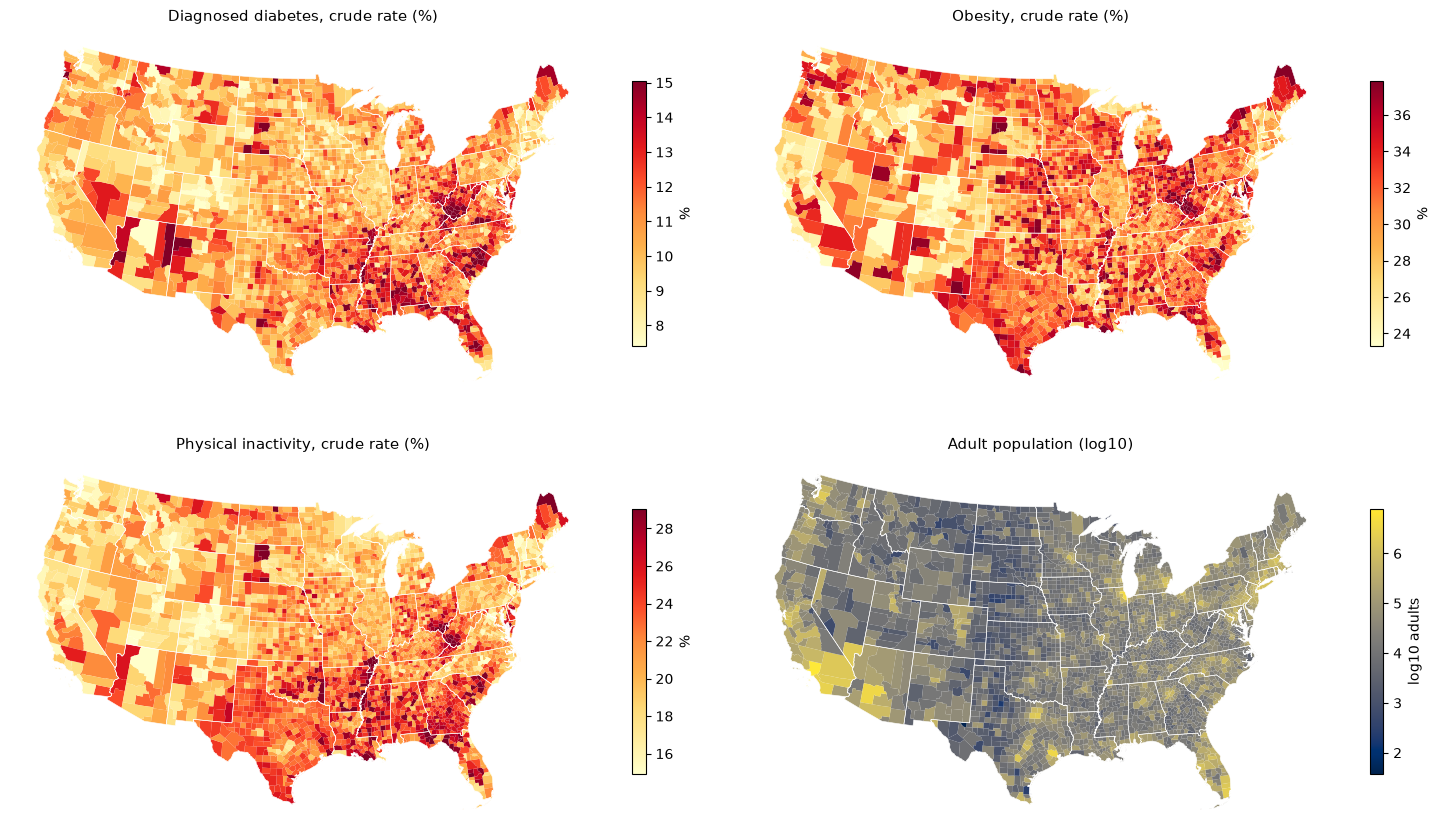

In [4]:
# Choropleth of county values with state boundaries drawn on top
def county_map(ax, values, title, cmap="viridis", vmin=None, vmax=None, norm_=None, cbar_label=""):
    kw = {"norm": norm_} if norm_ is not None else {"vmin": vmin, "vmax": vmax}
    gdf.assign(_v=np.asarray(values, float)).plot(column="_v", ax=ax, cmap=cmap, linewidth=0, legend=True,
                                                  legend_kwds={"shrink": 0.6, "label": cbar_label},
                                                  missing_kwds={"color": "lightgrey"}, **kw)
    states.boundary.plot(ax=ax, color="white", linewidth=0.4)
    ax.set_title(title, fontsize=11)
    ax.set_axis_off()

# Crude rates, with colours limited to the 2nd and 98th percentiles
fig, axes = plt.subplots(2, 2, figsize=(15, 9))
for ax, v in zip(axes.flat[:3], VARS):
    lo, hi = np.percentile(RATE[v], [2, 98])
    county_map(ax, RATE[v], f"{LABEL[v]}, crude rate (%)", "YlOrRd", lo, hi, cbar_label="%")
# Adult population on a log scale: counties run from a few dozen adults to millions
county_map(axes[1, 1], np.log10(POP), "Adult population (log10)", "cividis", cbar_label="log10 adults")
plt.tight_layout(); plt.show()

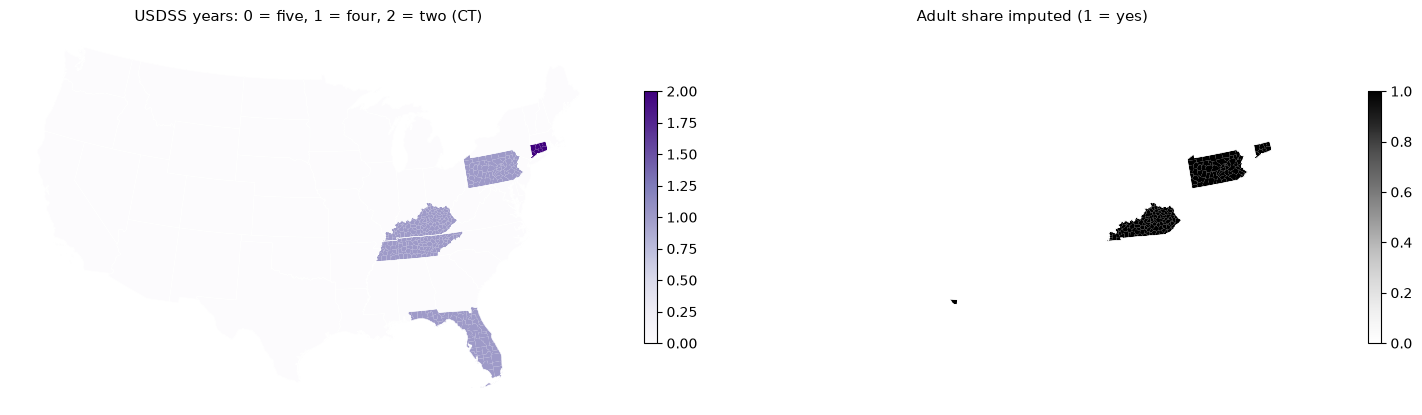

In [5]:
# Where the USDSS series covers fewer than five years, and where the adult share was imputed
fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))
county_map(axes[0], np.where(gdf["flag_ct_2020_21_only"], 2, gdf["flag_partial_years"].astype(int)),
           "USDSS years: 0 = five, 1 = four, 2 = two (CT)", "Purples", 0, 2)
county_map(axes[1], gdf["adult_share_imputed"].astype(int), "Adult share imputed (1 = yes)", "Greys", 0, 1)
plt.tight_layout(); plt.show()

**Reading the results.**

- **Size.** 3,108 counties hold 258.0 million adults, 26.0 million of them with diagnosed diabetes (a national crude rate of 10.1%), 76.8 million with obesity (29.8%) and 52.1 million physically inactive (20.2%).
- **Population.** County adult populations range from 37 (Loving County, Texas) to 7.8 million (Los Angeles County). The median is 20,600, and one county in ten has fewer than 3,900 adults. That range is why a Poisson model is needed.
- **Diabetes.** Crude rates are highest across the Southeast, the Mississippi Delta, Appalachia (West Virginia and eastern Kentucky), and parts of Arizona and New Mexico (Apache County, Arizona, 15.5%; McKinley County, New Mexico, 15.2%). They are lowest in Colorado, the northern Rockies and parts of the upper Midwest and New England.
- **Obesity and inactivity.** Both follow the southern and Appalachian pattern of diabetes, but obesity is also high across the Midwest and the northern Plains, where diabetes is moderate.
- **Gaps.** 357 counties average fewer than five years: the 349 counties of Florida, Kentucky, Pennsylvania and Tennessee, and the eight former Connecticut counties (2020 and 2021 only). The adult share is imputed in 196 counties (120 in Kentucky, 67 in Pennsylvania, 8 in Connecticut and one in Texas), so the population at risk in those states is less certain than elsewhere.

## Exploratory analysis

### How noisy are the rates?

If every county had the same risk, the rates would scatter only by Poisson chance, and that scatter shrinks as the population grows. A funnel plot shows the rates against population with Poisson control limits around the national rate. Counties outside the limits differ by more than chance.

The second plot compares two measures of the error of a county estimate: the Poisson standard deviation of the crude rate, 100 √(m/n), which the Poisson cokriging model assumes, and the USDSS standard error of the count expressed as a rate, 100 se/n, which comes from the small-area model.

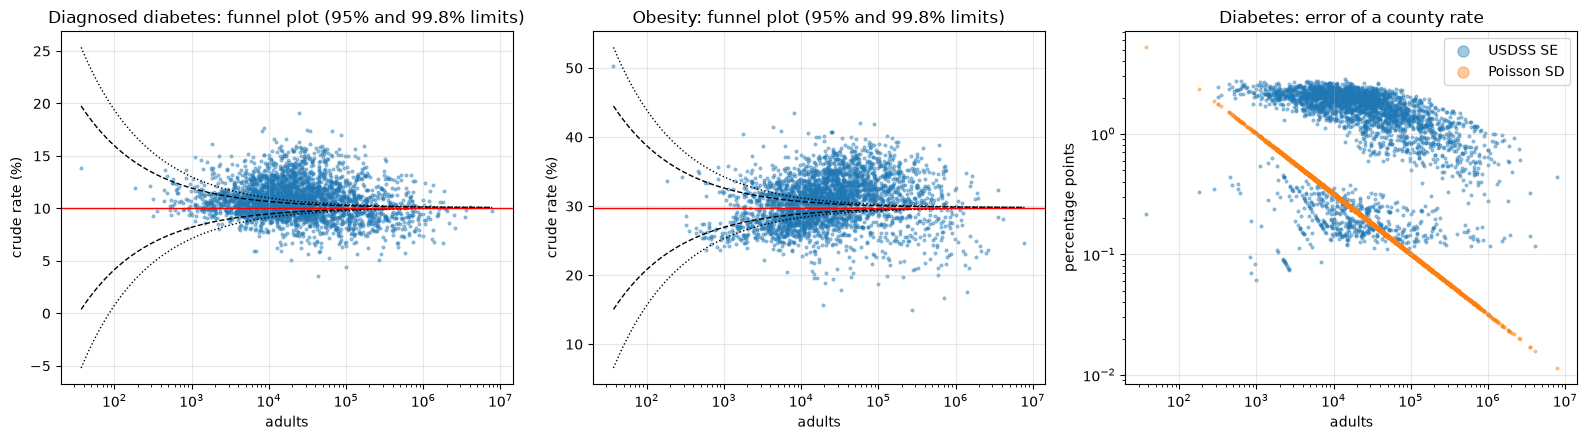

,outside 99.8% limits (%),variance of rates,mean Poisson variance,ratio
Diagnosed diabetes,63.803,3.164,0.130,24.328
Obesity,72.909,12.590,0.385,32.737
Physical inactivity,74.131,11.436,0.261,43.800


In [6]:
# National crude rates, and a population grid for drawing the funnel limits
m_nat = {v: CASES[v].sum() / POP.sum() for v in VARS}
nn = np.logspace(np.log10(POP.min()), np.log10(POP.max()), 200)

fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
for ax, v in zip(axes[:2], ["diab", "obes"]):
    p = m_nat[v]
    ax.scatter(POP, RATE[v], s=4, alpha=0.4)
    # 1.96 and 3.09 are the 95% and 99.8% normal limits around the national rate
    for z, ls in [(1.96, "--"), (3.09, ":")]:
        half = PR * z * np.sqrt(p * (1 - p) / nn)
        ax.plot(nn, PR * p + half, "k", ls=ls, lw=1); ax.plot(nn, PR * p - half, "k", ls=ls, lw=1)
    ax.axhline(PR * p, color="red", lw=1)
    ax.set_xscale("log"); ax.set_xlabel("adults"); ax.set_ylabel("crude rate (%)")
    ax.set_title(f"{LABEL[v]}: funnel plot (95% and 99.8% limits)")

# Poisson standard deviation of the diabetes rate, set beside the USDSS standard error
pois_sd = PR * np.sqrt(m_nat["diab"] / POP)
usdss_se = PR * gdf["diab_cases_se"].to_numpy() / POP
axes[2].scatter(POP, usdss_se, s=4, alpha=0.4, label="USDSS SE")
axes[2].scatter(POP, pois_sd, s=4, alpha=0.4, label="Poisson SD")
axes[2].set_xscale("log"); axes[2].set_yscale("log")
axes[2].set_xlabel("adults"); axes[2].set_ylabel("percentage points")
axes[2].set_title("Diabetes: error of a county rate"); axes[2].legend(markerscale=4)
plt.tight_layout(); plt.show()

# Share of counties outside the 99.8% limits, and the ratio of rate variance to Poisson variance
outside = {v: np.mean(np.abs(RATE[v] - PR * m_nat[v]) > PR * 3.09 * np.sqrt(m_nat[v] * (1 - m_nat[v]) / POP)) for v in VARS}
expected_var = {v: np.mean(PR**2 * m_nat[v] / POP) for v in VARS}
pd.DataFrame({
    "outside 99.8% limits (%)": [100 * outside[v] for v in VARS],
    "variance of rates": [RATE[v].var() for v in VARS],
    "mean Poisson variance": [expected_var[v] for v in VARS],
    "ratio": [RATE[v].var() / expected_var[v] for v in VARS],
}, index=[LABEL[v] for v in VARS]).round(3)

In [7]:
# Ratio of the published USDSS standard error to the Poisson standard deviation
ratio_se = usdss_se / pois_sd
print(f"USDSS SE / Poisson SD for diabetes: median {np.median(ratio_se):.1f}, "
      f"10th to 90th percentile {np.percentile(ratio_se, 10):.1f} to {np.percentile(ratio_se, 90):.1f}")
print(f"Median USDSS SE: {np.median(usdss_se):.2f} points; median Poisson SD: {np.median(pois_sd):.2f} points")

USDSS SE / Poisson SD for diabetes: median 7.1, 10th to 90th percentile 1.0 to 14.6
Median USDSS SE: 1.65 points; median Poisson SD: 0.22 points


**Reading the results.**

- **Real differences between counties, far above Poisson noise.** 64% of counties lie outside the 99.8% Poisson limits for diabetes, and 73% and 74% for obesity and inactivity. The variance of the county rates is 24 times the mean Poisson variance for diabetes, 33 times for obesity and 44 times for inactivity. Most of the variation between counties is variation in risk, not chance. The Poisson term matters only in the smallest counties.
- **The data carry much more error than Poisson implies.** The median USDSS standard error of a county diabetes rate is 1.65 percentage points, about seven times the Poisson standard deviation (0.22 points). Most counties form an upper band in the third plot; a smaller group has standard errors close to the Poisson line.

So the Poisson reliability term understates how uncertain the input estimates are. It is kept as the main model, because it is the method under study, and Section 7 repeats the analysis with the USDSS standard errors as the error term.

### Correlation of the three risks

Pearson correlations of the crude rates and of the USDSS age-adjusted percentages, and the empirical Bayes rates (`eb_risk`), which shrink each crude rate towards the national rate according to its population. Because the populations are large, the empirical Bayes z-scores keep the rank order of the crude rates.

crude rates                                   age-adjusted                            
                    Diagnosed diabetes Obesity Physical inactivity Diagnosed diabetes Obesity Physical inactivity
Diagnosed diabetes                1.00    0.51                0.66               1.00    0.63                0.77
Obesity                           0.51    1.00                0.69               0.63    1.00                0.69
Physical inactivity               0.66    0.69                1.00               0.77    0.69                1.00

Spearman correlation of EB z-scores with crude rates: {'diab': np.float64(1.0), 'obes': np.float64(1.0), 'inact': np.float64(1.0)}
Crude vs age-adjusted diabetes, Pearson r = 0.82
Diabetes crude rate vs share aged 65+, r = 0.3


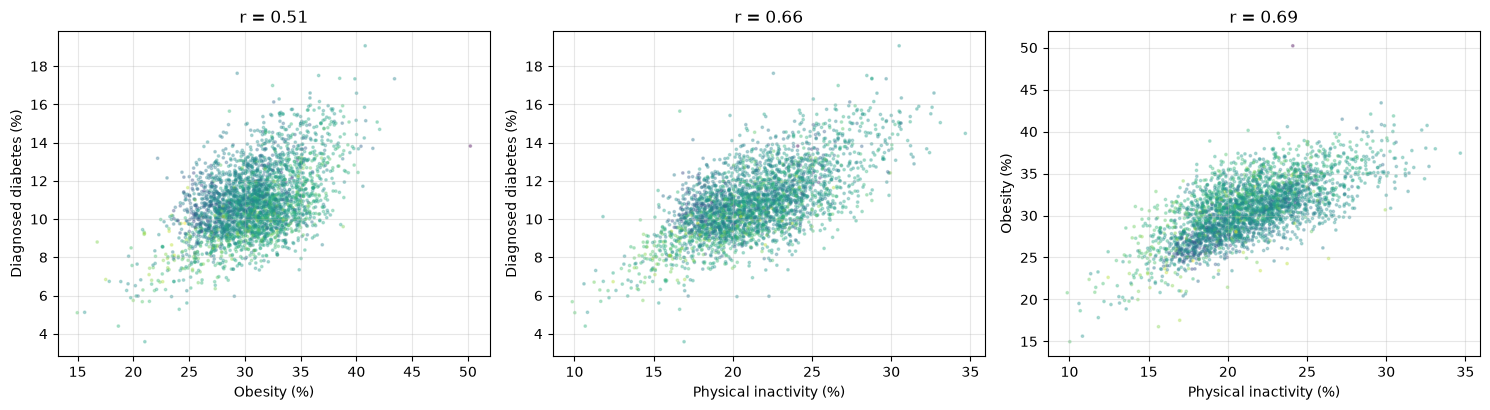

In [8]:
# Correlation among crude rates, and among the age-adjusted percentages
crude = pd.DataFrame({LABEL[v]: RATE[v] for v in VARS})
aa = pd.DataFrame({LABEL["diab"]: gdf["diab_pct_aa"], LABEL["obes"]: gdf["obes_pct_aa"],
                   LABEL["inact"]: gdf["inact_pct_aa"]})
corr = pd.concat({"crude rates": crude.corr(), "age-adjusted": aa.corr()}, axis=1).round(2)
display(corr)

# Empirical Bayes rates pull small counties toward the national rate
eb = {v: mpk.eb_risk(CASES[v], POP, pop_rate=PR) for v in VARS}
print("Spearman correlation of EB z-scores with crude rates:",
      {v: round(stats.spearmanr(eb[v], RATE[v])[0], 3) for v in VARS})
print("Crude vs age-adjusted diabetes, Pearson r =", round(np.corrcoef(RATE["diab"], gdf["diab_pct_aa"])[0, 1], 2))
print("Diabetes crude rate vs share aged 65+, r =",
      round(gdf[["diab_rate", "pct_65plus"]].dropna().corr().iloc[0, 1], 2))

# Pairwise crude rates, coloured by adult population
fig, axes = plt.subplots(1, 3, figsize=(15, 4.2))
for ax, (a, b) in zip(axes, [("obes", "diab"), ("inact", "diab"), ("inact", "obes")]):
    ax.scatter(RATE[a], RATE[b], s=3, alpha=0.3, c=np.log10(POP), cmap="viridis")
    ax.set_xlabel(f"{LABEL[a]} (%)"); ax.set_ylabel(f"{LABEL[b]} (%)")
    ax.set_title(f"r = {np.corrcoef(RATE[a], RATE[b])[0, 1]:.2f}")
plt.tight_layout(); plt.show()

In [9]:
# Population-weighted rates, so a large county counts in proportion to its adults
def pop_weighted(group):
    out = {}
    for v in VARS:
        out[LABEL[v] + " (%)"] = PR * group[f"{v}_cases" if v != "inact" else "inact_cases_approx"].sum() / group["pop_adult"].sum()
    out["counties"] = len(group)
    out["adults (millions)"] = group["pop_adult"].sum() / 1e6
    return pd.Series(out)

# Census regions, and the USDSS urban-rural flag
region_tab = gdf.groupby("region").apply(pop_weighted)
ur_tab = gdf.assign(ur=gdf["usdss_urban_rural"].map({1: "urban", 2: "rural"})).groupby("ur").apply(pop_weighted)
pd.concat({"region": region_tab, "USDSS urban-rural": ur_tab}).round(2)

Diagnosed diabetes (%)  Obesity (%)  Physical inactivity (%)  counties  adults (millions)
region            Midwest                     10.22        31.97                    20.47    1055.0              53.50
                  Northeast                    9.52        27.70                    20.10     217.0              45.49
                  South                       10.79        30.99                    21.68    1422.0              99.34
                  West                         9.15        27.33                    17.61     414.0              59.67
USDSS urban-rural rural                       11.35        30.60                    21.69    1311.0              14.50
                  urban                        9.99        29.72                    20.12    1797.0             243.50

**Reading the results.**

- **The three risks are related.** The crude rate of diabetes correlates with obesity at 0.51 and with inactivity at 0.66. The age-adjusted percentages correlate more strongly (0.63 and 0.77).
- **Age separates crude and age-adjusted rates.** Crude and age-adjusted diabetes correlate at 0.82, and the crude rate rises with the share of adults aged 65 and over (r = 0.30). Diabetes becomes more common with age, so counties with older populations have higher crude rates than their age-adjusted rates suggest.
- **Regions.** The South has the highest population-weighted rates (10.8% diabetes, 31.0% obesity, 21.7% inactivity) and the West the lowest (9.2%, 27.3% and 17.6%). Rural counties have higher diabetes rates than urban ones (11.4% against 10.0%).

## Population-weighted Poisson semivariograms

The semivariogram of risk is estimated from rates whose noise depends on population. Payares-Garcia et al. (2024, Eq. 12) weight each pair of counties by w = nᵢnⱼ/(nᵢ+nⱼ) and subtract the Poisson bias term, so pairs of small counties count less and the nugget created by Poisson noise is removed:

γ(h) = [Σ w (rᵢ − rⱼ)² − N(h) · bias] / (2 Σ w).

The cross-semivariogram (Eq. 13) uses the product of the two rate differences, and its bias term is the mean joint risk of the two diseases, r_lk = ρ √(R_l R_k) (`shared_risk`). Here ρ is the correlation of the two crude rates, as an estimate of the Poisson correlation of the counts within a county.

> **Package fix.** Before this capstone, `pck_variogram`, `poisson_cokrige` and `poisson_krige` scaled the Poisson bias and reliability terms by `pop_rate` instead of `pop_rate²`, which is correct only for `pop_rate = 1`. The terms now use the variance of a Poisson rate on the `pop_rate` scale, pop_rate² m*/n, so results in percent are exactly 100 times the results in proportions. The check below confirms this.

In [10]:
# Scale check: percent (pop_rate = 100) against proportions (pop_rate = 1)
g1 = mpk.pck_variogram(XY, CASES["diab"], POP, pop_rate=1, maxd=MAXD, nbins=NBINS)[1]
g100 = mpk.pck_variogram(XY, CASES["diab"], POP, pop_rate=PR, maxd=MAXD, nbins=NBINS)[1]
print("max |gamma(percent) - 100^2 gamma(proportion)| =", float(np.abs(g100 - PR**2 * g1).max()))

max |gamma(percent) - 100^2 gamma(proportion)| = 8.881784197001252e-16


In [11]:
# Three outcomes. Their crude-rate correlation is the within-county Poisson correlation.
P_ALL = len(VARS)
PAIRS = [(a, b) for a in range(P_ALL) for b in range(a + 1, P_ALL)]
RHO = np.corrcoef([RATE[v] for v in VARS])

# Population-weighted Poisson semivariograms for a chosen set of counties
def empirical_variograms(idx_by_var, maxd=MAXD, nbins=NBINS):
    # idx_by_var: one index array per variable (the counties where it is observed).
    # Direct variograms use each variable's own counties, cross-variograms the shared ones.
    dv, cv, shared = [], [], {}
    for l, v in enumerate(VARS[:len(idx_by_var)]):
        o = idx_by_var[l]
        dv.append(mpk.pck_variogram(XY[o], CASES[v][o], POP[o], pop_rate=PR, maxd=maxd, nbins=nbins))
    P = len(idx_by_var)
    for a, b in [(a, b) for a in range(P) for b in range(a + 1, P)]:
        o = np.intersect1d(idx_by_var[a], idx_by_var[b])
        va, vb = VARS[a], VARS[b]
        rlk = mpk.shared_risk(RATE[va][o], RATE[vb][o], RHO[a, b])
        shared[(a, b)] = float(np.mean(rlk))
        cv.append(mpk.pck_crossvariogram(XY[o], CASES[va][o], CASES[vb][o], POP[o], rlk,
                                         pop_rate=PR, maxd=maxd, nbins=nbins))
    return dv, cv, shared

# All counties out to 800 km for the fit, and out to 1,600 km for the longer plot
ALL = np.arange(len(gdf))
t0 = time.time()
DV, CV, SHARED = empirical_variograms([ALL] * P_ALL)
DV_LONG, CV_LONG, _ = empirical_variograms([ALL] * P_ALL, maxd=1600, nbins=32)
print(f"Empirical (cross-)semivariograms in {time.time() - t0:.1f} s")
print("Mean shared risk r_lk (percent):", {f"{VARS[a]}-{VARS[b]}": round(s, 2) for (a, b), s in SHARED.items()})
print("Pairs in the first lag class:", int(DV[0][2][0]))

Empirical (cross-)semivariograms in 7.5 s
Mean shared risk r_lk (percent): {'diab-obes': 9.32, 'diab-inact': 9.98, 'obes-inact': 17.51}
Pairs in the first lag class: 6320


## Linear model of coregionalization

The LMC uses one spatial structure with a common range for all three risks, plus a nugget:

C_lk(h) = B0_lk · 1(h = 0) + B_lk · exp(−h/a).

`fit_lmc` fits each entry of the nugget matrix B0 and the sill matrix B by weighted least squares (weights are the numbers of pairs), chooses the common range a by a grid search over all six semivariograms, and projects B0 and B to the nearest positive semi-definite matrices, which is what makes the model valid for cokriging. The fit uses lags up to 800 km, where the neighbourhoods used for kriging lie. The paper used a stable model with no nugget; the package offers exponential and spherical structures, and the county data need a nugget (see below).

In [12]:
# Common range on a 25 km grid. The exponential model with a nugget is the one used below.
RANGE_GRID = np.arange(100, 1501, 25)
lmc_exp = mpk.fit_lmc(DV, CV, PAIRS, P_ALL, 300, model="Exp", fit_range=True, nugget=True, range_grid=RANGE_GRID)
lmc_sph = mpk.fit_lmc(DV, CV, PAIRS, P_ALL, 600, model="Sph", fit_range=True, nugget=True, range_grid=RANGE_GRID)
lmc_nonug = mpk.fit_lmc(DV, CV, PAIRS, P_ALL, 300, model="Exp", fit_range=True, nugget=False, range_grid=RANGE_GRID)
LMC = lmc_exp
for name, m in [("Exponential + nugget (main model)", lmc_exp), ("Spherical + nugget", lmc_sph),
                ("Exponential, no nugget", lmc_nonug)]:
    extra = f" (practical range {3 * m.range:.0f} km)" if m.model == "Exp" else ""
    print(f"{name}: range parameter {m.range:.0f} km{extra}")

# Nugget B0, structured sill B, and the correlations each matrix implies
lab = [LABEL[v] for v in VARS]
tabs = {
    "nugget B0": pd.DataFrame(LMC.B0, lab, lab),
    "structured sill B": pd.DataFrame(LMC.B, lab, lab),
    "structural correlation": pd.DataFrame(LMC.correlation(), lab, lab),
}
d0 = np.sqrt(np.clip(np.diag(LMC.B0), 1e-12, None))
tabs["nugget correlation"] = pd.DataFrame(LMC.B0 / np.outer(d0, d0), lab, lab)
display(pd.concat(tabs, axis=0).round(3))
# Nugget share of each sill. Positive eigenvalues mean the LMC is valid for cokriging.
print("Nugget share of the total sill:", {v: round(LMC.B0[l, l] / LMC.sill(l), 2) for l, v in enumerate(VARS)})
print("Eigenvalues of B :", np.round(np.linalg.eigvalsh(LMC.B), 3))
print("Eigenvalues of B0:", np.round(np.linalg.eigvalsh(LMC.B0), 3))

Exponential + nugget (main model): range parameter 325 km (practical range 975 km)
Spherical + nugget: range parameter 725 km
Exponential, no nugget: range parameter 100 km (practical range 300 km)


Diagnosed diabetes  Obesity  Physical inactivity
nugget B0              Diagnosed diabetes                1.927    3.025                2.607
                       Obesity                           3.025    9.773                5.887
                       Physical inactivity               2.607    5.887                7.462
structured sill B      Diagnosed diabetes                1.430    0.991                1.572
                       Obesity                           0.991    2.938                2.217
                       Physical inactivity               1.572    2.217                3.467
structural correlation Diagnosed diabetes                1.000    0.483                0.706
                       Obesity                           0.483    1.000                0.695
                       Physical inactivity               0.706    0.695                1.000
nugget correlation     Diagnosed diabetes                1.000    0.697                0.688
                       Obesity                           0.697    1.000                0.689
                       Physical inactivity               0.688    0.689                1.000

Nugget share of the total sill: {'diab': np.float64(0.57), 'obes': np.float64(0.77), 'inact': np.float64(0.68)}
Eigenvalues of B : [0.533 1.151 6.151]
Eigenvalues of B0: [ 0.771  2.623 15.768]


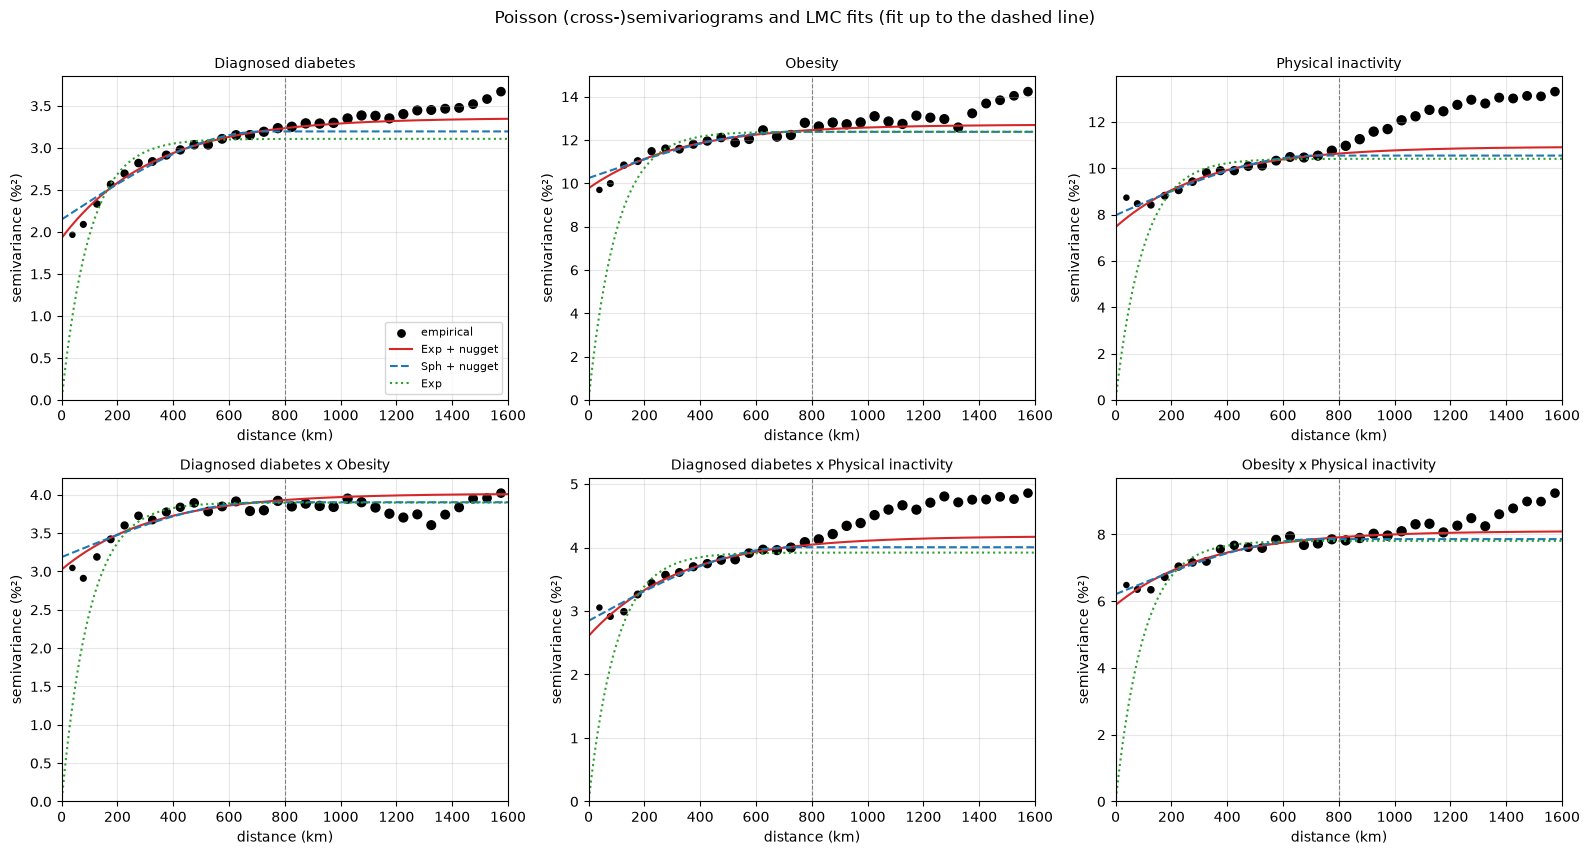

In [13]:
# Empirical semivariograms out to 1,600 km, with the three fitted curves
fig, axes = plt.subplots(2, 3, figsize=(16, 8.5))
hh = np.linspace(1, 1600, 300)
panels = [(l, l) for l in range(P_ALL)] + PAIRS
# Diagonal panels are direct semivariograms; the off-diagonal panels are cross-semivariograms
for ax, (a, b) in zip(axes.flat, panels):
    if a == b:
        lg, gm, npair = DV_LONG[a]; title = f"{LABEL[VARS[a]]}"
    else:
        lg, gm, npair = CV_LONG[PAIRS.index((a, b))]; title = f"{LABEL[VARS[a]]} x {LABEL[VARS[b]]}"
    # Marker area grows with the number of county pairs in the lag
    ax.scatter(lg, gm, s=12 + 30 * npair / npair.max(), color="k", label="empirical")
    for m, c, ls in [(lmc_exp, "C3", "-"), (lmc_sph, "C0", "--"), (lmc_nonug, "C2", ":")]:
        ax.plot(hh, m.gamma(a, b, hh), c, ls=ls, label=f"{m.model}{' + nugget' if np.any(m.B0) else ''}")
    # Vertical line marks the 800 km distance used to fit the model
    ax.axvline(MAXD, color="grey", lw=0.8, ls="--")
    ax.set_xlim(0, 1600); ax.set_ylim(0, None)
    ax.set_title(title, fontsize=10); ax.set_xlabel("distance (km)"); ax.set_ylabel("semivariance (%²)")
axes[0, 0].legend(fontsize=8)
plt.suptitle("Poisson (cross-)semivariograms and LMC fits (fit up to the dashed line)", y=1.0)
plt.tight_layout(); plt.show()

**Reading the results.**

- **Shape.** All six semivariograms rise steeply over the first 200 km and then slowly. Inactivity and the diabetes-inactivity cross-semivariogram keep rising beyond 800 km, which reflects the broad contrast between the South and the West. The LMC is fitted up to 800 km, the scale that matters for local kriging, and the long-range rise is left to the local neighbourhoods.
- **Main model.** The exponential model with a nugget fits best, with a common range parameter of 325 km (practical range about 975 km). The spherical model gives almost the same curves with a range of 725 km. Without a nugget, the fitted range drops to the lower end of the search grid (100 km) and the model misses the semivariograms near the origin.
- **A large nugget.** The nugget is 57% of the total sill for diabetes, 77% for obesity and 68% for inactivity. The Poisson noise has already been removed from the semivariograms, so this is variation between neighbouring counties that the 50 km lag classes cannot resolve, plus the error of the USDSS estimates.
- **Correlation sits in both parts.** The structural correlation of diabetes is 0.48 with obesity and 0.71 with inactivity. The nugget correlations are about 0.69 for every pair. So a county's own obesity and inactivity carry information about its diabetes even where its neighbours do not, which is what co-located cokriging uses.
- **Valid model.** All eigenvalues of B and B0 are positive, so the fitted LMC is positive definite.

## Smoothing: leave-one-out estimates of diabetes risk

For every county, diabetes risk is estimated from the k = 32 nearest diabetes counts of the other counties, and, for cokriging, from the 32 nearest obesity and inactivity counts, including those of the county itself. Comparing the estimate with the county's own rate is a leave-one-out cross-validation. Three estimators are compared:

- **PK:** univariate Poisson kriging of diabetes.
- **PCK-2:** Poisson cokriging with obesity.
- **PCK-3:** Poisson cokriging with obesity and inactivity.

The scores follow the paper: mean error (bias), mean absolute error, mean squared prediction error (MSPE) and Pearson's ρ between estimate and observed rate. The z-scores, error divided by kriging standard deviation, should have a mean near 0 and a standard deviation near 1 if the kriging variance is right, and 90% of rates should fall inside the 90% intervals.

In [14]:
# Coregionalization of the first P variables, in the order diabetes, obesity, inactivity
def sub_lmc(lmc, P):
    return mpk.LMC(lmc.B[:P, :P], lmc.range, lmc.model, lmc.B0[:P, :P])

# One record per variable: coordinates, counts, and population where that variable is observed
def datasets(P, target_idx=ALL, aux_idx=None, noise=None):
    # Target (diabetes) at target_idx; auxiliaries at aux_idx (default: all counties).
    aux_idx = aux_idx or [ALL] * (P - 1)
    idx = [target_idx] + list(aux_idx)
    out = []
    for l in range(P):
        o, v = idx[l], VARS[l]
        d = dict(x=XY[o, 0], y=XY[o, 1], cases=CASES[v][o], pop=POP[o])
        if noise is not None:
            d["noise_var"] = noise[v][o]
        out.append(d)
    return out

# Bias, absolute and squared error, correlation, and coverage of the 90% interval
def scores(pred, var, obs):
    e = pred - obs
    sd = np.sqrt(np.clip(var, 1e-12, None))
    z = e / sd
    return {"ME": e.mean(), "MAE": np.abs(e).mean(), "MSPE": np.mean(e**2),
            "rho": np.corrcoef(pred, obs)[0, 1], "z mean": z.mean(), "z SD": z.std(),
            "cover 90%": np.mean(np.abs(e) <= norm.ppf(0.95) * sd)}

# Leave-one-out Poisson kriging, or cokriging with obesity and optionally inactivity
def smooth(P, lmc=None, k=K, mean_rate="global", noise=None):
    lmc = sub_lmc(lmc or LMC, P)
    return mpk.poisson_cokrige(datasets(P, noise=noise), 0, lmc, pop_rate=PR, shared_mean=SHARED,
                               smooth=True, number_of_neighbors=k, mean_rate=mean_rate, use_gpu=USE_GPU)

# PK is diabetes alone, PCK-2 adds obesity, and PCK-3 adds inactivity as well
SM, rows = {}, {}
for P, name in [(1, "PK"), (2, "PCK-2"), (3, "PCK-3")]:
    t0 = time.time()
    SM[name] = smooth(P)
    rows[name] = scores(SM[name]["rate_pred"], SM[name]["rate_var"], RATE["diab"])
    rows[name]["seconds"] = time.time() - t0
smooth_tab = pd.DataFrame(rows).T
smooth_tab["MSPE drop vs PK (%)"] = 100 * (1 - smooth_tab["MSPE"] / smooth_tab.loc["PK", "MSPE"])
smooth_tab.round(3)

,ME,MAE,MSPE,rho,z mean,z SD,cover 90%,seconds,MSPE drop vs PK (%)
PK,-0.019,1.042,1.893,0.634,-0.012,0.917,0.922,0.057,0.000
PCK-2,-0.025,0.939,1.438,0.741,-0.016,1.073,0.881,0.070,24.023
PCK-3,-0.023,0.884,1.293,0.771,-0.014,1.113,0.864,0.088,31.690


In [15]:
# Check: univariate PK through poisson_krige gives the same answer as P = 1 cokriging
pk_check = mpk.poisson_krige(datasets(1)[0], LMC.B[0, 0], LMC.range, nugget=LMC.B0[0, 0], pop_rate=PR,
                             smooth=True, number_of_neighbors=K, mean_rate="global", use_gpu=USE_GPU)
print("max |poisson_krige - poisson_cokrige(P=1)| =", float(np.abs(pk_check["rate_pred"] - SM["PK"]["rate_pred"]).max()))

max |poisson_krige - poisson_cokrige(P=1)| = 0.0


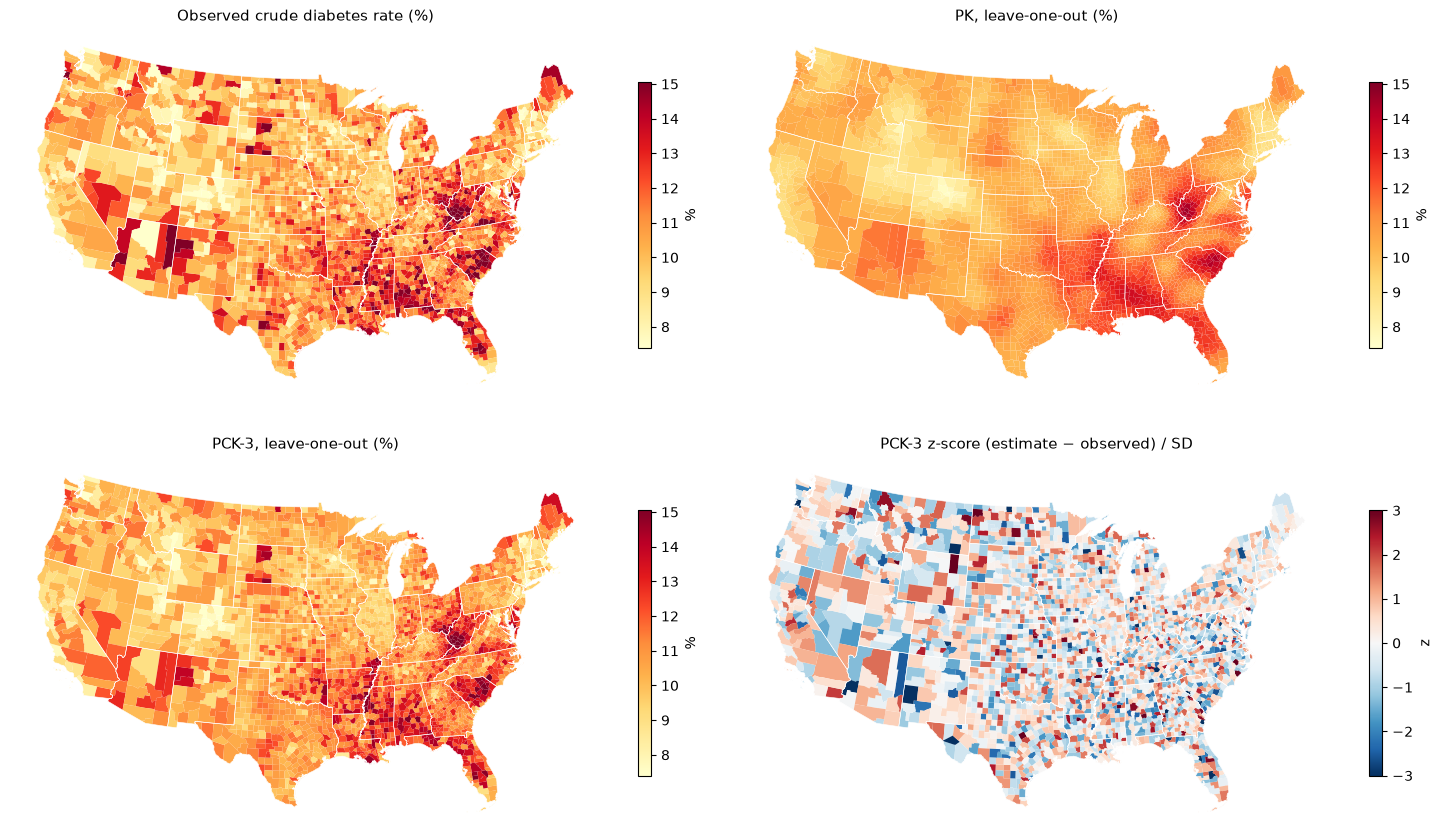

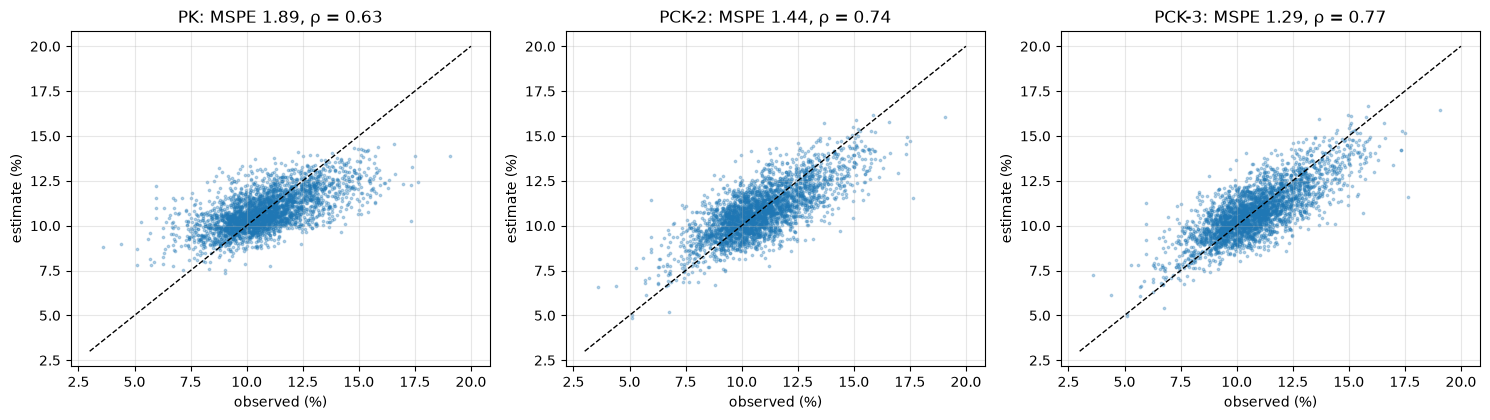

In [16]:
# Leave-one-out maps on one colour scale, and the standardized PCK-3 residual
lo, hi = np.percentile(RATE["diab"], [2, 98])
fig, axes = plt.subplots(2, 2, figsize=(15, 9))
county_map(axes[0, 0], RATE["diab"], "Observed crude diabetes rate (%)", "YlOrRd", lo, hi, cbar_label="%")
county_map(axes[0, 1], SM["PK"]["rate_pred"], "PK, leave-one-out (%)", "YlOrRd", lo, hi, cbar_label="%")
county_map(axes[1, 0], SM["PCK-3"]["rate_pred"], "PCK-3, leave-one-out (%)", "YlOrRd", lo, hi, cbar_label="%")
county_map(axes[1, 1], SM["PCK-3"]["zscore"], "PCK-3 z-score (estimate − observed) / SD", "RdBu_r",
           norm_=TwoSlopeNorm(0, -3, 3), cbar_label="z")
plt.tight_layout(); plt.show()

# Observed rate against the estimate. The dashed line is equality.
fig, axes = plt.subplots(1, 3, figsize=(15, 4.3))
for ax, name in zip(axes, ["PK", "PCK-2", "PCK-3"]):
    ax.scatter(RATE["diab"], SM[name]["rate_pred"], s=3, alpha=0.3)
    ax.plot([3, 20], [3, 20], "k--", lw=1)
    ax.set_xlabel("observed (%)"); ax.set_ylabel("estimate (%)")
    ax.set_title(f"{name}: MSPE {smooth_tab.loc[name, 'MSPE']:.2f}, ρ = {smooth_tab.loc[name, 'rho']:.2f}")
plt.tight_layout(); plt.show()

**Reading the results.**

- **Cokriging improves the estimate a lot.** The MSPE falls from 1.89 for PK to 1.44 with obesity (24% lower) and 1.29 with obesity and inactivity (32% lower). The correlation with the observed rate rises from 0.63 to 0.74 and 0.77, and the mean absolute error falls from 1.04 to 0.88 points. All three are almost unbiased (mean error −0.02 points).
- **The maps show why.** PK can only borrow from neighbours, so its map is a regional surface. PCK-3 also uses the county's own obesity and inactivity, so it recovers county detail, for example high single counties in the Dakotas (Todd, Dewey and Rolette), southeastern Missouri and southern Ohio.
- **Cokriging intervals are slightly too narrow.** The z-scores have a standard deviation of 0.92 for PK and 1.11 for PCK-3, and 92% and 86% of rates fall inside the 90% intervals. The single common range and the PSD projection make the LMC tie diabetes to the auxiliaries a little more tightly than the data support in some regions (Section 6 shows Florida).
- **Speed.** With k = 32 neighbours per variable, smoothing all 3,108 counties takes about one second for PCK-3.

## Prediction where diabetes is missing

The paper's main use of Poisson cokriging is prediction where the target is not observed: counties with suppressed counts, or areas outside a survey. The USDSS data are complete, so missing data are created by hiding diabetes:

- **Random masks.** Diabetes is hidden in 30%, 50% or 65% of counties, chosen at random; obesity and inactivity stay observed everywhere. Each design is repeated with different masks.
- **The paper's design.** Diabetes observed in 35% of counties, obesity in 70% (including those 35%) and inactivity in all, as in the simulation of Payares-Garcia et al. (2024).
- **State holdouts.** Diabetes is hidden for a whole state: Kentucky, Tennessee, Florida and Pennsylvania, the four states with a year missing in USDSS. Predictions there must come from neighbouring states and from the state's own obesity and inactivity.

In every replicate the semivariograms and the LMC are refitted from the observed data only, so the hidden counties play no part in the model. The predicted risk is compared with the hidden crude rate.

In [17]:
# Refit the semivariograms and the LMC using only the counties still observed
def fit_from(idx_by_var):
    dv, cv, shared = empirical_variograms(idx_by_var)
    P = len(idx_by_var)
    pairs = [(a, b) for a in range(P) for b in range(a + 1, P)]
    lmc = mpk.fit_lmc(dv, cv, pairs, P, 300, model="Exp", fit_range=True, nugget=True, range_grid=RANGE_GRID)
    return lmc, shared

# Predict the hidden counties. Obesity and inactivity can still be observed there.
def predict_hidden(hidden, idx_by_var, lmc, shared, P, k=K):
    obs_idx = [idx_by_var[0]] + list(idx_by_var[1:P])
    ds = datasets(P, target_idx=obs_idx[0], aux_idx=obs_idx[1:])
    r = mpk.poisson_cokrige(ds, 0, sub_lmc(lmc, P), pop_rate=PR, shared_mean=shared,
                            coords_pred=XY[hidden], number_of_neighbors=k, mean_rate="global", use_gpu=USE_GPU)
    return r["pred"], r["var"]

# Random masks, the paper's 35/70/100 design, and four whole-state holdouts
rng = np.random.default_rng(SEED)
pred_rows, keep_preds = [], {}
t0 = time.time()

designs = [(f"random {int(100 * f)}% hidden", f) for f in (0.30, 0.50, 0.65)] + [("paper: 35 / 70 / 100%", None)]
for name, frac in designs:
    for rep in range(N_REPS):
        # Hide a random share of diabetes counts. Obesity and inactivity stay observed everywhere.
        if frac is not None:
            hidden = np.sort(rng.choice(len(gdf), int(round(frac * len(gdf))), replace=False))
            obs_t = np.setdiff1d(ALL, hidden)
            idx_by_var = [obs_t, ALL, ALL]
        else:
            # Paper design: diabetes in 35% of counties, obesity in 70%, inactivity in every county
            perm = rng.permutation(len(gdf))
            obs_t = np.sort(perm[: int(0.35 * len(gdf))])
            obs_o = np.sort(perm[: int(0.70 * len(gdf))])
            hidden = np.setdiff1d(ALL, obs_t)
            idx_by_var = [obs_t, obs_o, ALL]
        lmc_r, shared_r = fit_from(idx_by_var)
        for P, est in [(1, "PK"), (2, "PCK-2"), (3, "PCK-3")]:
            pr_, va_ = predict_hidden(hidden, idx_by_var, lmc_r, shared_r, P)
            pred_rows.append({"design": name, "rep": rep, "estimator": est, "range": lmc_r.range,
                              **scores(pr_, va_, RATE["diab"][hidden])})

# Hide diabetes for one whole state and predict it from the rest of the country
for st in HOLDOUT_STATES:
    hidden = np.flatnonzero(gdf["state"].to_numpy() == st)
    obs_t = np.setdiff1d(ALL, hidden)
    idx_by_var = [obs_t, ALL, ALL]
    lmc_r, shared_r = fit_from(idx_by_var)
    for P, est in [(1, "PK"), (2, "PCK-2"), (3, "PCK-3")]:
        pr_, va_ = predict_hidden(hidden, idx_by_var, lmc_r, shared_r, P)
        keep_preds[(st, est)] = (hidden, pr_, va_)
        pred_rows.append({"design": f"state: {st}", "rep": 0, "estimator": est, "range": lmc_r.range,
                          **scores(pr_, va_, RATE["diab"][hidden])})
print(f"Prediction experiments: {time.time() - t0:.0f} s")
PRED = pd.DataFrame(pred_rows)

Prediction experiments: 77 s


In [18]:
# Mean score over replicates, and the drop in squared error relative to univariate PK
cols = ["ME", "MAE", "MSPE", "rho", "z SD", "cover 90%"]
order = [d for d, _ in designs] + [f"state: {s}" for s in HOLDOUT_STATES]
pred_tab = PRED.groupby(["design", "estimator"])[cols].mean()
pred_tab = pred_tab.reindex(pd.MultiIndex.from_product([order, ["PK", "PCK-2", "PCK-3"]], names=["design", "estimator"]))
pk_mspe = pred_tab["MSPE"].xs("PK", level="estimator")
pred_tab["MSPE drop vs PK (%)"] = [100 * (1 - m / pk_mspe[d]) for (d, e), m in pred_tab["MSPE"].items()]
pred_tab.round(3)

ME    MAE   MSPE    rho   z SD  cover 90%  MSPE drop vs PK (%)
design                estimator                                                                   
random 30% hidden     PK        -0.048  1.054  1.935  0.618  0.911      0.921                0.000
                      PCK-2     -0.040  0.956  1.490  0.727  1.086      0.875               22.964
                      PCK-3     -0.034  0.899  1.335  0.760  1.133      0.859               31.012
random 50% hidden     PK        -0.031  1.089  2.066  0.598  0.952      0.912                0.000
                      PCK-2     -0.045  0.985  1.582  0.718  1.124      0.862               23.454
                      PCK-3     -0.042  0.922  1.406  0.754  1.162      0.850               31.975
random 65% hidden     PK        -0.038  1.097  2.073  0.580  0.930      0.919                0.000
                      PCK-2     -0.056  0.998  1.610  0.703  1.092      0.874               22.344
                      PCK-3     -0.056  0.935  1.441  0.740  1.157      0.848               30.503
paper: 35 / 70 / 100% PK        -0.019  1.097  2.084  0.584  0.932      0.917                0.000
                      PCK-2     -0.031  1.043  1.821  0.652  1.021      0.894               12.590
                      PCK-3     -0.041  0.932  1.443  0.740  1.091      0.875               30.755
state: Kentucky       PK         0.611  1.295  2.606  0.407  0.976      0.883                0.000
                      PCK-2      0.312  0.974  1.672  0.601  1.075      0.842               35.861
                      PCK-3      0.286  0.958  1.525  0.634  1.124      0.833               41.487
state: Tennessee      PK         0.289  1.119  2.115  0.265  0.934      0.916                0.000
                      PCK-2      0.214  0.962  1.476  0.589  1.066      0.863               30.210
                      PCK-3      0.016  0.988  1.547  0.572  1.216      0.842               26.870
state: Florida        PK        -0.999  1.971  5.311  0.065  1.209      0.776                0.000
                      PCK-2     -1.079  1.460  3.493  0.648  1.114      0.761               34.227
                      PCK-3     -1.102  1.542  3.911  0.608  1.293      0.776               26.365
state: Pennsylvania   PK         1.085  1.414  2.974  0.105  0.854      0.896                0.000
                      PCK-2      0.689  1.112  1.826  0.193  0.967      0.836               38.605
                      PCK-3      0.535  1.056  1.588  0.224  1.032      0.896               46.581

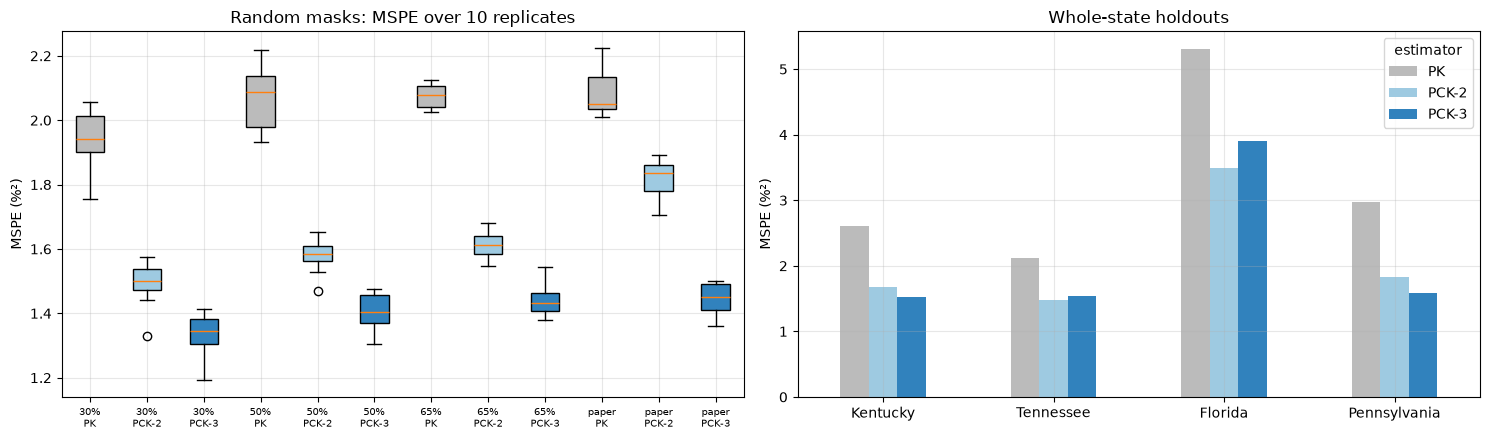

In [19]:
# Whether the cokriging gain is stable across the random-mask replicates
fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))
rand = PRED[~PRED["design"].str.startswith("state")]
data_box, labels = [], []
for d, _ in designs:
    for est in ["PK", "PCK-2", "PCK-3"]:
        data_box.append(rand[(rand["design"] == d) & (rand["estimator"] == est)]["MSPE"].to_numpy())
        labels.append(f"{d.split(' hidden')[0].replace('random ', '').split(':')[0]}\n{est}")
bp = axes[0].boxplot(data_box, tick_labels=labels, patch_artist=True)
for i, box in enumerate(bp["boxes"]):
    box.set_facecolor(["#bbbbbb", "#9ecae1", "#3182bd"][i % 3])
axes[0].tick_params(axis="x", labelsize=7); axes[0].set_ylabel("MSPE (%²)")
axes[0].set_title(f"Random masks: MSPE over {N_REPS} replicates")

# Squared error when a whole state's diabetes counts are hidden
st_tab = pred_tab.loc[[f"state: {s}" for s in HOLDOUT_STATES], "MSPE"].unstack()[["PK", "PCK-2", "PCK-3"]]
st_tab.index = HOLDOUT_STATES
st_tab.plot.bar(ax=axes[1], color=["#bbbbbb", "#9ecae1", "#3182bd"], rot=0)
axes[1].set_ylabel("MSPE (%²)"); axes[1].set_title("Whole-state holdouts")
plt.tight_layout(); plt.show()

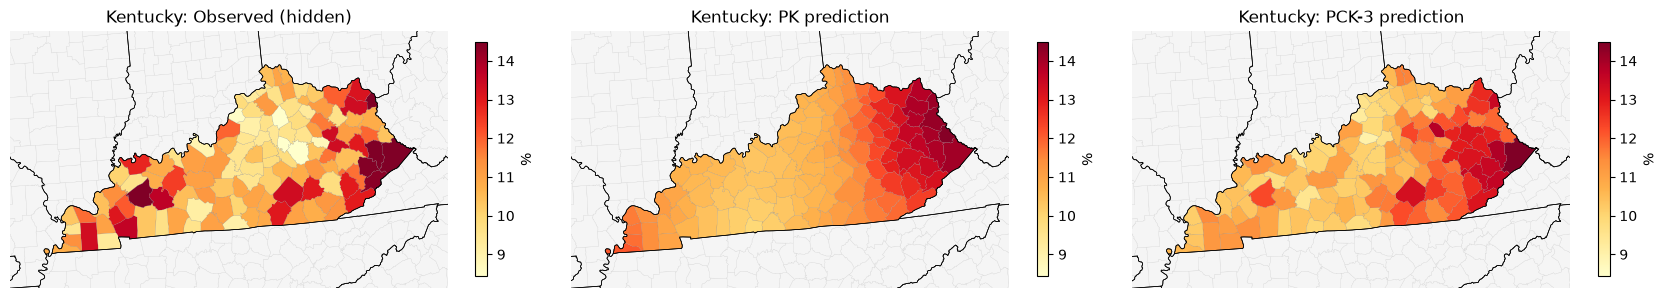

In [20]:
# Kentucky held out: observed diabetes beside the PK and PCK-3 predictions
st = "Kentucky"
hidden, _, _ = keep_preds[(st, "PK")]
sub = gdf.iloc[hidden]
xmin, ymin, xmax, ymax = sub.total_bounds
lo, hi = np.percentile(RATE["diab"][hidden], [2, 98])
fig, axes = plt.subplots(1, 3, figsize=(17, 4.2))
for ax, (title, vals) in zip(axes, [("Observed (hidden)", RATE["diab"][hidden]),
                                    ("PK prediction", keep_preds[(st, "PK")][1]),
                                    ("PCK-3 prediction", keep_preds[(st, "PCK-3")][1])]):
    gdf.plot(ax=ax, color="whitesmoke", edgecolor="lightgrey", linewidth=0.2)
    sub.assign(_v=vals).plot(column="_v", ax=ax, cmap="YlOrRd", vmin=lo, vmax=hi, legend=True,
                             legend_kwds={"shrink": 0.6, "label": "%"}, linewidth=0.1, edgecolor="grey")
    states.boundary.plot(ax=ax, color="k", linewidth=0.5)
    # Pad the frame by 60 km so the state outline is fully visible
    ax.set_xlim(xmin - 6e4, xmax + 6e4); ax.set_ylim(ymin - 6e4, ymax + 6e4)
    ax.set_title(f"{st}: {title}"); ax.set_axis_off()
plt.tight_layout(); plt.show()

**Reading the results.**

- **Random masks.** PCK-3 lowers the MSPE by 30% to 32% at all three masking levels (PK 1.94 to 2.07, PCK-3 1.34 to 1.44), and raises ρ from about 0.60 to about 0.75. The gain hardly changes as more counties are hidden, because obesity and inactivity are still observed in every hidden county.
- **The paper's design.** With obesity missing in 30% of counties, PCK-2 gains only 13%, but adding inactivity, which is observed everywhere, brings the gain back to 31%. The auxiliary that is observed at the prediction location matters most.
- **Intervals.** PK covers 91% to 92% of the hidden rates with its 90% intervals; PCK-3 covers 85% to 86%.
- **States.** Cokriging lowers the MSPE by 41% in Kentucky (2.61 to 1.53) and 47% in Pennsylvania (2.97 to 1.59). PK overestimates both states (by 0.61 and 1.09 points), because their neighbours have higher rates; the auxiliaries cut that bias roughly in half. The Kentucky maps show PCK-3 recovering county highs in the east and west that PK smooths away.
- **Florida and Tennessee need care.** In both, PCK-2 beats PCK-3 (Florida 3.49 against 3.91, Tennessee 1.48 against 1.55). Florida is underestimated by about one point by every estimator: its crude rate is high because its population is old, and the inactivity count, built from an age-adjusted percentage, does not carry that age effect.
- **Pennsylvania.** Even with cokriging, ρ within Pennsylvania is only 0.22. Its adult shares are imputed (Section 1), which adds error to the crude rates the predictions are compared with.

## Sensitivity

The leave-one-out smoothing of Section 5 is repeated with one choice changed at a time. PK and PCK-3 are shown, so the gain from cokriging can be seen under each choice.

- **Neighbourhood size:** k = 8, 16, 64 and 128 instead of 32.
- **Covariance model:** spherical instead of exponential, and exponential with no nugget.
- **Range:** the fitted range halved and doubled.
- **Mean rate in the Poisson term:** the local rate of the neighbours (the package default) instead of the national rate.
- **Error term:** the USDSS standard error (100 se/n)² instead of the Poisson variance.
- **Rounded counts:** the five-year means rounded to integers.

In [21]:
# Same coregionalization with the range rescaled
def with_range(lmc, factor):
    return mpk.LMC(lmc.B, lmc.range * factor, lmc.model, lmc.B0)

# Extra variance from the published USDSS standard errors, on the percent scale
USDSS_NOISE = {
    "diab": (PR * gdf["diab_cases_se"].to_numpy() / POP) ** 2,
    "obes": (PR * gdf["obes_cases_se"].to_numpy() / POP) ** 2,
    "inact": (gdf["inact_pct_aa_se"].to_numpy()) ** 2,     # USDSS gives inactivity as a percentage with its SE
}

# One change at a time: neighbourhood, covariance, range, mean rate, or the USDSS error term
runs = [("main: Exp + nugget, k = 32", dict())]
runs += [(f"k = {k}", dict(k=k)) for k in (8, 16, 64, 128)]
runs += [("spherical + nugget", dict(lmc=lmc_sph)), ("exponential, no nugget", dict(lmc=lmc_nonug)),
         ("range x 0.5", dict(lmc=with_range(LMC, 0.5))), ("range x 2", dict(lmc=with_range(LMC, 2.0))),
         ("local mean rate", dict(mean_rate="local")), ("USDSS SE as error term", dict(noise=USDSS_NOISE))]
# Leave-one-out scores for PK and PCK-3 under each setting
sens = []
for name, kw in runs:
    for P, est in [(1, "PK"), (3, "PCK-3")]:
        r = smooth(P, **kw)
        sens.append({"setting": name, "estimator": est, **scores(r["rate_pred"], r["rate_var"], RATE["diab"])})

# Rounded counts: five-year means are fractional, so the scores are repeated on whole cases
saved = {v: CASES[v].copy() for v in VARS}
for v in VARS:
    CASES[v] = np.round(saved[v])
for P, est in [(1, "PK"), (3, "PCK-3")]:
    r = smooth(P)
    sens.append({"setting": "rounded counts", "estimator": est, **scores(r["rate_pred"], r["rate_var"], RATE["diab"])})
CASES.update(saved)

SENS = pd.DataFrame(sens)
sens_tab = SENS.pivot(index="setting", columns="estimator", values=["MSPE", "rho", "z SD", "cover 90%"])
sens_tab[("MSPE drop (%)", "")] = 100 * (1 - sens_tab[("MSPE", "PCK-3")] / sens_tab[("MSPE", "PK")])
sens_tab.reindex([n for n, _ in runs] + ["rounded counts"]).round(3)

MSPE           rho          z SD        cover 90%        MSPE drop (%)
estimator                   PCK-3     PK  PCK-3     PK  PCK-3     PK     PCK-3     PK              
setting                                                                                            
main: Exp + nugget, k = 32  1.293  1.893  0.771  0.634  1.113  0.917     0.864  0.922        31.690
k = 8                       1.322  1.881  0.768  0.639  1.096  0.891     0.875  0.928        29.743
k = 16                      1.302  1.891  0.770  0.635  1.111  0.911     0.866  0.922        31.170
k = 64                      1.292  1.896  0.771  0.634  1.113  0.918     0.862  0.922        31.829
k = 128                     1.293  1.898  0.771  0.633  1.113  0.918     0.862  0.922        31.862
spherical + nugget          1.319  1.938  0.766  0.623  1.089  0.904     0.874  0.924        31.948
exponential, no nugget      1.392  1.958  0.761  0.631  1.735  1.542     0.700  0.798        28.918
range x 0.5                 1.280  1.860  0.774  0.642  1.055  0.872     0.881  0.935        31.182
range x 2                   1.315  1.935  0.766  0.624  1.158  0.951     0.850  0.911        32.018
local mean rate             1.292  1.893  0.771  0.634  1.112  0.917     0.864  0.922        31.740
USDSS SE as error term      1.353  1.976  0.765  0.618  0.929  0.914     0.924  0.922        31.540
rounded counts              1.293  1.893  0.771  0.634  1.113  0.917     0.864  0.922        31.698

**Reading the results.**

- **Neighbourhood.** Results are the same for k = 16 to 128 (MSPE 1.29 to 1.30 for PCK-3). Only k = 8 is slightly worse (1.32).
- **Model and range.** The spherical model and a halved or doubled range change the MSPE by less than 0.03, and the gain from cokriging stays between 29% and 32% in every setting.
- **The nugget is needed for honest variances.** Without it, the MSPE rises to 1.39 and the z-score SD to 1.74, and only 70% of rates fall in the 90% intervals.
- **The Poisson term is small here.** The local or global mean rate and rounding the counts to integers make no difference, because the Poisson variance is small next to the nugget in all but the smallest counties.
- **USDSS standard errors as the error term.** The MSPE of PCK-3 rises slightly (1.35), because large standard errors push each estimate further towards its neighbours. But the intervals become honest: the z-score SD is 0.93 and coverage is 92%. When the inputs are model-based estimates, their own standard errors are the better error term.

## Risk patterns and social context

The PCK-3 leave-one-out estimate is the diabetes risk expected in a county from its neighbours and from its own obesity and inactivity. Two quantities are mapped from it:

- **Probability of high risk.** P(risk > national crude rate), from a normal approximation with the PCK-3 estimate and kriging variance. Counties with a probability above 0.9 are flagged.
- **Local excess.** The z-score of the observed rate against the PCK-3 estimate, (observed − estimate)/SD. A positive value means more diabetes than the neighbours, obesity and inactivity predict.

Both are then related to the social and economic covariates with Spearman correlations, and summarized by state.

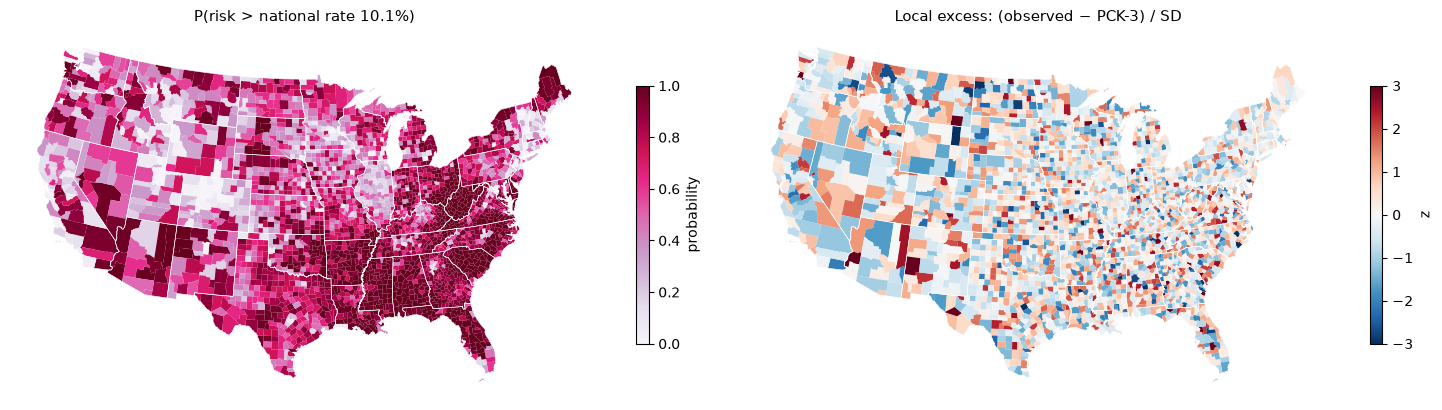

Counties with P(high) > 0.9: 954 (24.7% of adults)
Counties with excess z > 2: 130, z < -2: 104


In [22]:
# Chance that the smoothed risk exceeds the national rate, and the local excess of the observed rate
best = SM["PCK-3"]
sd_best = np.sqrt(np.clip(best["rate_var"], 1e-12, None))
nat = PR * m_nat["diab"]
gdf["pck3_risk"] = best["rate_pred"]
gdf["pck3_sd"] = sd_best
gdf["p_high"] = 1 - norm.cdf((nat - best["rate_pred"]) / sd_best)
gdf["excess_z"] = -best["zscore"]          # (observed − estimate) / SD

fig, axes = plt.subplots(1, 2, figsize=(15, 4.6))
county_map(axes[0], gdf["p_high"], f"P(risk > national rate {nat:.1f}%)", "PuRd", 0, 1, cbar_label="probability")
county_map(axes[1], gdf["excess_z"], "Local excess: (observed − PCK-3) / SD", "RdBu_r",
           norm_=TwoSlopeNorm(0, -3, 3), cbar_label="z")
plt.tight_layout(); plt.show()

# Counties with probability above 0.9, and counties whose excess z falls outside -2 to 2
print(f"Counties with P(high) > 0.9: {(gdf['p_high'] > 0.9).sum()} "
      f"({100 * gdf.loc[gdf['p_high'] > 0.9, 'pop_adult'].sum() / POP.sum():.1f}% of adults)")
print(f"Counties with excess z > 2: {(gdf['excess_z'] > 2).sum()}, z < -2: {(gdf['excess_z'] < -2).sum()}")

In [23]:
# Rank correlation of social covariates with the rate, the smoothed risk, and the local excess
COV = {"svi_2022": "Social Vulnerability Index", "pov_pct_2023": "Poverty (%)",
       "med_hh_income_2023": "Median household income", "unemp_rate_2020_23": "Unemployment (%)",
       "uninsured_pct": "Uninsured (%)", "food_env_index": "Food environment index",
       "pct_65plus": "Aged 65+ (%)", "pct_nh_black": "Non-Hispanic Black (%)",
       "pct_hispanic": "Hispanic (%)", "pct_rural": "Rural (%)", "diab_mortality": "Diabetes mortality"}
rows = {}
# Counties missing that covariate are left out of its correlation
for c, lab_ in COV.items():
    ok = gdf[c].notna()
    rows[lab_] = {
        "observed rate": stats.spearmanr(gdf.loc[ok, c], RATE["diab"][ok])[0],
        "PCK-3 risk": stats.spearmanr(gdf.loc[ok, c], gdf.loc[ok, "pck3_risk"])[0],
        "local excess z": stats.spearmanr(gdf.loc[ok, c], gdf.loc[ok, "excess_z"])[0],
        "n": int(ok.sum()),
    }
cov_tab = pd.DataFrame(rows).T
cov_tab["n"] = cov_tab["n"].astype(int)
cov_tab.round(2)

,observed rate,PCK-3 risk,local excess z,n
Social Vulnerability Index,0.36,0.49,-0.06,3100
Poverty (%),0.47,0.50,0.08,3100
Median household income,-0.53,-0.47,-0.19,3100
Unemployment (%),0.26,0.28,0.06,3108
Uninsured (%),0.28,0.38,-0.03,2912
Food environment index,-0.44,-0.44,-0.12,2912
Aged 65+ (%),0.30,-0.10,0.54,2912
Non-Hispanic Black (%),0.25,0.42,-0.12,2912
Hispanic (%),-0.26,-0.14,-0.20,2912
Rural (%),0.26,-0.02,0.39,2912


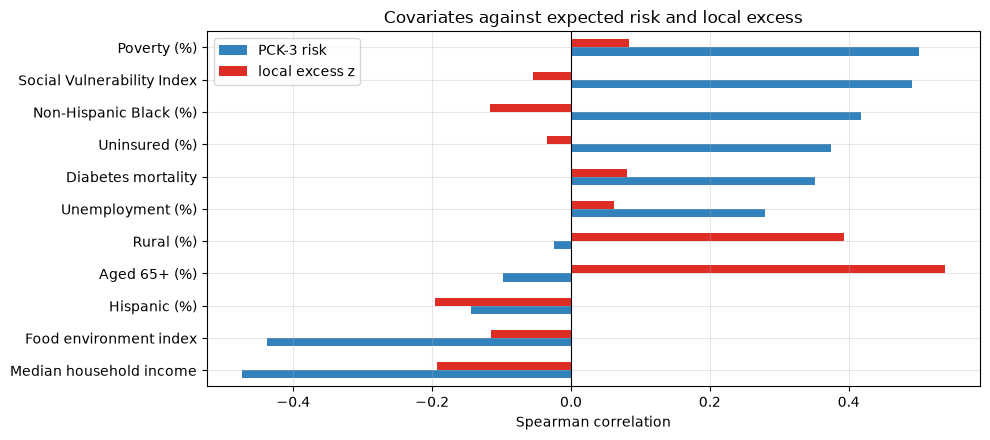

,observed rate (%),"PCK-3 risk (%, pop-weighted)",counties,P(high) > 0.9,excess z > 2,mean SD
state,,,,,,
West Virginia,13.64,13.41,55.0,50.0,6.0,1.00
Mississippi,12.56,13.08,82.0,70.0,3.0,1.01
South Carolina,12.26,12.74,46.0,40.0,6.0,1.00
Alabama,12.72,12.73,67.0,52.0,7.0,1.00
Arkansas,11.62,12.28,75.0,53.0,2.0,1.01
Louisiana,12.09,12.26,64.0,34.0,4.0,1.01
Delaware,12.06,11.98,3.0,2.0,0.0,1.00
Oklahoma,11.20,11.72,77.0,30.0,0.0,1.02
Indiana,11.11,11.45,92.0,34.0,4.0,0.99


In [24]:
# Which covariates follow the smoothed risk, and which follow the leftover local excess
fig, ax = plt.subplots(figsize=(10, 4.5))
cov_tab[["PCK-3 risk", "local excess z"]].sort_values("PCK-3 risk").plot.barh(ax=ax, color=["#3182bd", "#de2d26"])
ax.axvline(0, color="k", lw=0.8); ax.set_xlabel("Spearman correlation")
ax.set_title("Covariates against expected risk and local excess")
plt.tight_layout(); plt.show()

# States ordered by population-weighted PCK-3 risk
state_tab = gdf.groupby("state").apply(lambda g: pd.Series({
    "observed rate (%)": PR * g["diab_cases"].sum() / g["pop_adult"].sum(),
    "PCK-3 risk (%, pop-weighted)": np.average(g["pck3_risk"], weights=g["pop_adult"]),
    "counties": len(g),
    "P(high) > 0.9": int((g["p_high"] > 0.9).sum()),
    "excess z > 2": int((g["excess_z"] > 2).sum()),
    "mean SD": g["pck3_sd"].mean(),
}))
state_tab.sort_values("PCK-3 risk (%, pop-weighted)", ascending=False).head(12).round(2)

**Reading the results.**

- **High risk.** 954 counties, home to 24.7% of adults, have a probability above 0.9 that their diabetes risk exceeds the national crude rate of 10.1%. 691 of them are in the South, covering most of the Southeast, the Mississippi Delta and Appalachia, and 183 in the Midwest. West Virginia, Mississippi, Alabama, South Carolina, Arkansas and Louisiana have the highest population-weighted risk (12.3% to 13.4%).
- **Expected risk follows social disadvantage.** The PCK-3 risk correlates with poverty (0.50), the Social Vulnerability Index (0.49), the share of non-Hispanic Black residents (0.42) and the uninsured share (0.38), and negatively with median household income (−0.47) and the food environment index (−0.44).
- **The local excess is about age.** 130 counties have more diabetes than PCK-3 expects (z above 2), and 104 less. The excess correlates most with the share aged 65 and over (0.54) and the rural share (0.39), and hardly at all with poverty or SVI. Counties older than their neighbours have more diabetes than neighbours, obesity and inactivity predict, because crude risk depends on age and the inactivity input is age-adjusted. Age is the next variable to add (Exercise 5).

## Uncertainty

The paper's Figure 7b maps the cokriging variance as a map of reliability. Here the PCK-3 standard deviation is mapped, together with the reduction of the variance relative to PK, and plotted against the two things that drive it: the county's population, through the Poisson term, and how far away its neighbours are.

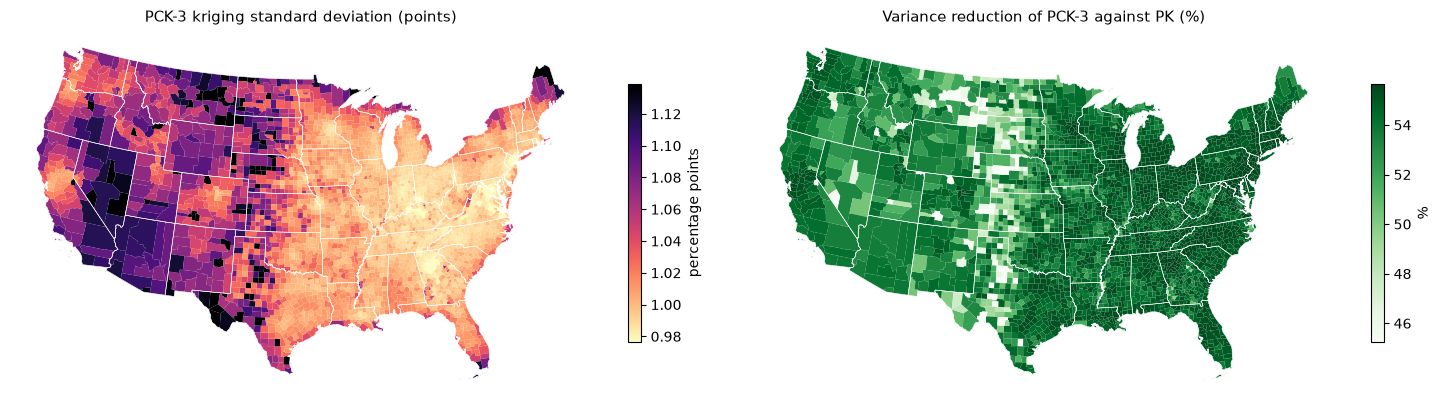

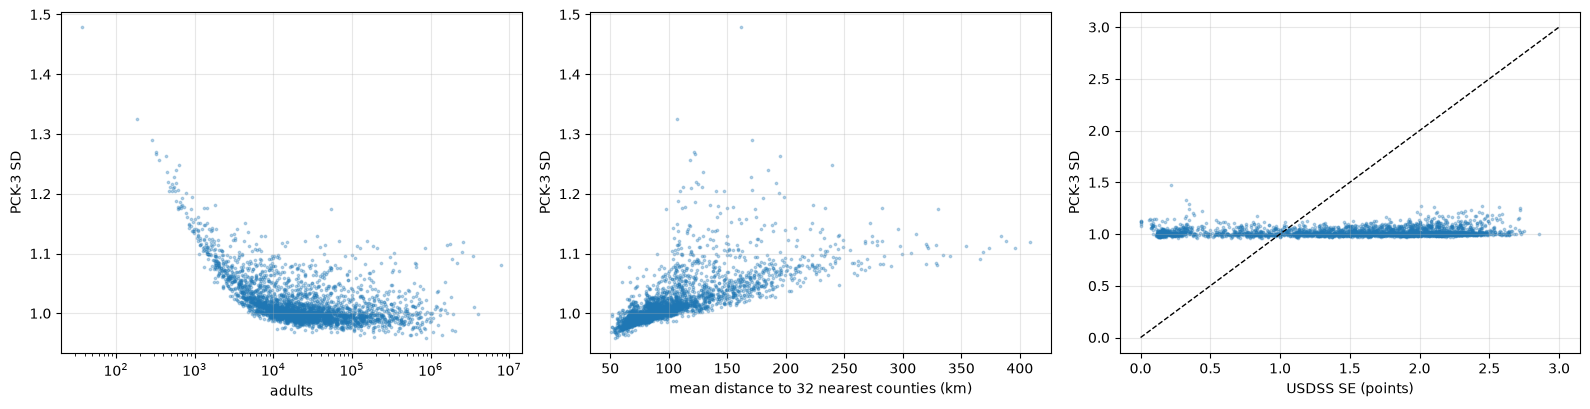

Spearman: SD vs adults -0.54 | SD vs neighbour distance 0.84 | SD vs USDSS SE 0.09
Variance reduction: median 54.6%, 10th to 90th percentile 51.7 to 55.4%
Least reliable counties (largest PCK-3 SD):


,state,county,pop_adult,diab_rate,pck3_risk,pck3_sd
452,Texas,Loving County,37.04,13.82,10.45,1.48
128,Texas,King County,182.96,11.92,11.62,1.33
2395,Texas,Kenedy County,286.29,12.16,10.22,1.29
2448,Nebraska,McPherson County,318.30,10.87,9.91,1.27
149,Nebraska,Arthur County,318.54,9.23,9.72,1.27
257,Montana,Petroleum County,436.48,11.78,9.62,1.26
174,Nebraska,Blaine County,351.78,9.72,10.14,1.26
2432,Nevada,Esmeralda County,632.74,12.30,10.37,1.25


In [25]:
# How much cokriging shrinks the variance relative to univariate PK
var_red = 100 * (1 - SM["PCK-3"]["rate_var"] / SM["PK"]["rate_var"])
# The nearest neighbour returned is the county itself, so the mean uses the other K
dist_nb, _ = cKDTree(XY).query(XY, k=K + 1)
mean_nb_dist = dist_nb[:, 1:].mean(1)

# Where the kriging standard deviation is large, and where cokriging shrinks the variance most
fig, axes = plt.subplots(1, 2, figsize=(15, 4.6))
county_map(axes[0], sd_best, "PCK-3 kriging standard deviation (points)", "magma_r",
           *np.percentile(sd_best, [2, 98]), cbar_label="percentage points")
county_map(axes[1], var_red, "Variance reduction of PCK-3 against PK (%)", "Greens",
           *np.percentile(var_red, [2, 98]), cbar_label="%")
plt.tight_layout(); plt.show()

# Standard deviation against population, neighbour distance, and the USDSS standard error
fig, axes = plt.subplots(1, 3, figsize=(16, 4.2))
axes[0].scatter(POP, sd_best, s=3, alpha=0.3); axes[0].set_xscale("log")
axes[0].set_xlabel("adults"); axes[0].set_ylabel("PCK-3 SD")
axes[1].scatter(mean_nb_dist, sd_best, s=3, alpha=0.3)
axes[1].set_xlabel(f"mean distance to {K} nearest counties (km)"); axes[1].set_ylabel("PCK-3 SD")
axes[2].scatter(usdss_se, sd_best, s=3, alpha=0.3); axes[2].plot([0, 3], [0, 3], "k--", lw=1)
axes[2].set_xlabel("USDSS SE (points)"); axes[2].set_ylabel("PCK-3 SD")
plt.tight_layout(); plt.show()

print("Spearman: SD vs adults", round(stats.spearmanr(POP, sd_best)[0], 2),
      "| SD vs neighbour distance", round(stats.spearmanr(mean_nb_dist, sd_best)[0], 2),
      "| SD vs USDSS SE", round(stats.spearmanr(usdss_se, sd_best)[0], 2))
print(f"Variance reduction: median {np.median(var_red):.1f}%, 10th to 90th percentile "
      f"{np.percentile(var_red, 10):.1f} to {np.percentile(var_red, 90):.1f}%")
# Counties with the largest kriging standard deviation
print("Least reliable counties (largest PCK-3 SD):")
display(gdf.nlargest(8, "pck3_sd")[["state", "county", "pop_adult", "diab_rate", "pck3_risk", "pck3_sd"]].round(2))

**Reading the results.**

- **A floor set by the nugget.** The PCK-3 standard deviation lies between 0.96 and 1.48 points, with most counties close to 1.0. That floor is the nugget: variation between neighbouring counties that neither the neighbours nor the auxiliaries can predict.
- **Where reliability is lowest.** The largest standard deviations are in the sparsely populated Great Plains and the interior West, in counties with a few hundred adults or fewer (Loving, King and Kenedy in Texas; McPherson, Arthur and Blaine in Nebraska). The standard deviation falls with population (Spearman −0.54) and rises with the distance to the neighbours (0.84).
- **Cokriging roughly halves the variance.** PCK-3 has 52% to 55% less kriging variance than PK in most counties, with the smallest reductions along the Great Plains.
- **Two different uncertainties.** The kriging standard deviation is almost unrelated to the USDSS standard error (Spearman 0.09). The first measures how well a county's risk can be predicted from the others; the second measures the uncertainty of the USDSS estimate itself. Both are needed to judge a county value.

## Summary

- **Data.** Five-year means of USDSS diabetes, obesity and inactivity counts for 3,108 counties, with adult populations from 37 to 7.8 million. Between-county differences in risk are far larger than Poisson noise, and the USDSS standard errors are about seven times the Poisson standard deviation.
- **Spatial structure.** One exponential structure (range parameter 325 km) plus a large nugget (57% of the diabetes sill) fits all six Poisson semivariograms. Diabetes is correlated with obesity and inactivity both in the structured part (0.48 and 0.71) and in the nugget (about 0.69).
- **Smoothing.** Trivariate Poisson cokriging lowers the leave-one-out MSPE of diabetes risk by 32% against univariate Poisson kriging (1.29 against 1.89) and raises ρ from 0.63 to 0.77.
- **Prediction.** With diabetes hidden in 30% to 65% of counties, the gain is 30% to 32%. For whole states it is 26% to 47%. The gain comes mainly from the auxiliary data at the prediction location.
- **Limits of the auxiliaries.** Florida and Tennessee show that an age-adjusted auxiliary can mislead for a crude target. The local excess of diabetes is explained mostly by age.
- **Uncertainty.** Cokriging roughly halves the kriging variance, but its 90% intervals cover 86% of rates. Using the USDSS standard errors as the error term gives honest intervals (92%).
- **Package.** The k-NN leave-one-out smoothing, heterotopic k-NN prediction, the LMC nugget, user-supplied error variances and the `pop_rate` scaling fix were added to `multi_poisson_kriging` for this capstone.

### Limitations

- **Modelled counts.** The USDSS county counts are small-area model estimates. The Poisson model describes sampling noise in registered counts, which these data do not have, and the USDSS standard errors describe a different kind of uncertainty. The method is shown on realistic risk surfaces, but the reliability terms are not the true error of the data.
- **Crude against age-adjusted.** Crude diabetes risk depends strongly on age, while the inactivity count was built from an age-adjusted percentage. Counties with many older adults, such as much of Florida, are therefore harder to predict from inactivity.
- **One structure.** The LMC has one structure with a common range plus a nugget. The semivariograms keep rising beyond 800 km (the South against the West), which a local neighbourhood absorbs but a single global model does not describe.
- **Point support.** Counties are treated as points at their geometric centroids. The paper used population-weighted centroids; area-to-area Poisson kriging would use the population distribution inside each county.
- **Five-year means.** Averaging 2020 to 2024 hides trends, and four states have a year missing.
- **Shared risk.** The joint risk r_lk uses the correlation of county rates as the Poisson correlation within a county. Its effect is small here, because the Poisson terms are small next to the nugget.

### Exercises

1. Make obesity the target and diabetes and inactivity the auxiliaries. Is the gain from cokriging symmetric?
2. Fit the models to each year separately and predict the missing state-years (FL 2021, KY 2023, PA 2023, TN 2024), which are real missing data. Compare with the five-year model.
3. Add diabetes mortality as a fourth variable. Where is it missing, and does it help?
4. Replace the inactivity count with a crude count, for example by applying the age-adjusted percentage to the age structure of each county, and repeat the Florida holdout.
5. Use the share aged 65 and over as an external drift (regression with Poisson cokriging of the residual risk). How much of the PCK-3 gain remains?
6. Compute population-weighted centroids from census tracts and repeat Section 5.

## References

- Goovaerts, P. (2005). Geostatistical analysis of disease data: estimation of cancer mortality risk from empirical frequencies using Poisson kriging. *International Journal of Health Geographics*, 4, 31.
- Monestiez, P., Dubroca, L., Bonnin, E., Durbec, J.-P. and Guinet, C. (2006). Geostatistical modelling of spatial distribution of Balaenoptera physalus in the Northwestern Mediterranean Sea from sparse count data and heterogeneous observation efforts. *Ecological Modelling*, 193, 615-628.
- Payares-Garcia, D., Osei, F., Mateu, J. and Stein, A. (2024). Multivariate Poisson cokriging: a geostatistical model for health count data. *Statistical Methods in Medical Research*, 33(9), 1637-1659. doi:10.1177/09622802241268488
- Payares-Garcia, D., Osei, F., Stein, A. and Mateu, J. (2023). A Poisson cokriging method for bivariate count data. *Spatial Statistics*, 57, 100769.
- Wackernagel, H. (2003). *Multivariate Geostatistics*, 3rd ed. Springer.
- Centers for Disease Control and Prevention. U.S. Diabetes Surveillance System, county data 2020 to 2024. https://gis.cdc.gov/grasp/diabetes/diabetesatlas.html